# Preparaci?n del modelado inmobiliario ? Parte 2

Continuaci?n de `preparacion_modelado_inmobiliario.ipynb`. Esta parte contiene nuevas variantes del modelado a partir de los datasets ya generados.

## 34. Mercado est?ndar sin `total_area`

Partimos del dataset est?ndar de la secci?n 33 y eliminamos `total_area` para evaluar una alternativa frente a la colinealidad con `living_area`. La comparaci?n se realiza sobre el mismo conjunto temporal de prueba y se registra en MLflow.

In [1]:
from pathlib import Path

import mlflow
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest

CORTE_TEMPORAL = "2025-01"
VARIABLE_ELIMINADA_SECCION_34 = "total_area"
RUTA_ORIGEN_SECCION_34 = Path("data_sets_transformados/secondary_market_modelado_seccion_33.csv")
RUTA_SALIDA_SECCION_34 = Path("data_sets_transformados/secondary_market_modelado_seccion_34.csv")

df_seccion_33_origen = pd.read_csv(RUTA_ORIGEN_SECCION_34)
if VARIABLE_ELIMINADA_SECCION_34 not in df_seccion_33_origen.columns:
    raise KeyError(f"No se encontro la columna esperada: {VARIABLE_ELIMINADA_SECCION_34}")
if df_seccion_33_origen["price_per_sqm"].isna().any() or (df_seccion_33_origen["price_per_sqm"] <= 0).any():
    raise ValueError("price_per_sqm contiene valores faltantes, cero o negativos")

df_ols_seccion_34 = df_seccion_33_origen.drop(columns=[VARIABLE_ELIMINADA_SECCION_34]).copy()
df_ols_seccion_34.to_csv(RUTA_SALIDA_SECCION_34, index=False)

df_train_seccion_33 = df_seccion_33_origen[df_seccion_33_origen["periodo"] < CORTE_TEMPORAL].copy()
df_test_seccion_33 = df_seccion_33_origen[df_seccion_33_origen["periodo"] >= CORTE_TEMPORAL].copy()
df_train_seccion_34 = df_ols_seccion_34[df_ols_seccion_34["periodo"] < CORTE_TEMPORAL].copy()
df_test_seccion_34 = df_ols_seccion_34[df_ols_seccion_34["periodo"] >= CORTE_TEMPORAL].copy()

if df_train_seccion_34.empty or df_test_seccion_34.empty:
    raise ValueError("El corte temporal no produjo train y test validos")

X_train_seccion_33 = df_train_seccion_33.drop(columns=["price_per_sqm", "periodo"])
X_test_seccion_33 = df_test_seccion_33.drop(columns=["price_per_sqm", "periodo"])
X_train_seccion_34 = df_train_seccion_34.drop(columns=["price_per_sqm", "periodo"])
X_test_seccion_34 = df_test_seccion_34.drop(columns=["price_per_sqm", "periodo"])
y_train_seccion_33 = df_train_seccion_33["price_per_sqm"]
y_test_seccion_33 = df_test_seccion_33["price_per_sqm"]
y_train_seccion_34 = df_train_seccion_34["price_per_sqm"]
y_test_seccion_34 = df_test_seccion_34["price_per_sqm"]

X_train_seccion_33_sm = sm.add_constant(X_train_seccion_33, has_constant="add")
X_test_seccion_33_sm = sm.add_constant(X_test_seccion_33, has_constant="add")
X_train_seccion_34_sm = sm.add_constant(X_train_seccion_34, has_constant="add")
X_test_seccion_34_sm = sm.add_constant(X_test_seccion_34, has_constant="add")

resultados_ols_seccion_33 = sm.OLS(y_train_seccion_33, X_train_seccion_33_sm).fit()
resultados_ols_seccion_34 = sm.OLS(y_train_seccion_34, X_train_seccion_34_sm).fit()
predicciones_test_seccion_33 = resultados_ols_seccion_33.predict(X_test_seccion_33_sm)
predicciones_train_seccion_34 = resultados_ols_seccion_34.predict(X_train_seccion_34_sm)
predicciones_test_seccion_34 = resultados_ols_seccion_34.predict(X_test_seccion_34_sm)

def calcular_metricas_regresion(y_real, predicciones, prefijo):
    errores_porcentuales = (y_real - predicciones) / y_real
    return {
        f"mae_{prefijo}": float(mean_absolute_error(y_real, predicciones)),
        f"rmse_{prefijo}": float(mean_squared_error(y_real, predicciones) ** 0.5),
        f"r2_{prefijo}": float(r2_score(y_real, predicciones)),
        f"mape_{prefijo}": float(errores_porcentuales.abs().mean() * 100)
    }

metricas_ols_seccion_33_mismo_test = calcular_metricas_regresion(
    y_test_seccion_33, predicciones_test_seccion_33, "test"
)
metricas_ols_seccion_34 = {
    **calcular_metricas_regresion(y_train_seccion_34, predicciones_train_seccion_34, "train"),
    **calcular_metricas_regresion(y_test_seccion_34, predicciones_test_seccion_34, "test"),
    "r2_ols": float(resultados_ols_seccion_34.rsquared),
    "r2_ajustado_ols": float(resultados_ols_seccion_34.rsquared_adj),
    "aic_ols": float(resultados_ols_seccion_34.aic),
    "bic_ols": float(resultados_ols_seccion_34.bic),
    "f_statistic_ols": float(resultados_ols_seccion_34.fvalue),
    "prob_f_statistic_ols": float(resultados_ols_seccion_34.f_pvalue),
    "condition_number_ols": float(resultados_ols_seccion_34.condition_number),
    "coeficientes_significativos_005": float((resultados_ols_seccion_34.pvalues <= 0.05).sum()),
    "coeficientes_no_significativos_005": float((resultados_ols_seccion_34.pvalues > 0.05).sum()),
    "filas_entrenamiento": float(len(df_train_seccion_34)),
    "filas_prueba": float(len(df_test_seccion_34))
}
omnibus_seccion_34, prob_omnibus_seccion_34 = omni_normtest(resultados_ols_seccion_34.resid)
jarque_bera_seccion_34, prob_jb_seccion_34, skew_seccion_34, kurtosis_seccion_34 = jarque_bera(resultados_ols_seccion_34.resid)
metricas_ols_seccion_34.update({
    "omnibus_ols": float(omnibus_seccion_34),
    "prob_omnibus_ols": float(prob_omnibus_seccion_34),
    "durbin_watson_ols": float(durbin_watson(resultados_ols_seccion_34.resid)),
    "jarque_bera_ols": float(jarque_bera_seccion_34),
    "prob_jb_ols": float(prob_jb_seccion_34),
    "skew_ols": float(skew_seccion_34),
    "kurtosis_ols": float(kurtosis_seccion_34)
})
coeficientes_ols_seccion_34 = pd.DataFrame({
    "variable": resultados_ols_seccion_34.params.index,
    "coeficiente": resultados_ols_seccion_34.params.to_numpy(),
    "p_value": resultados_ols_seccion_34.pvalues.to_numpy(),
    "significativa_0_05": resultados_ols_seccion_34.pvalues.to_numpy() <= 0.05
})
residuos_test_seccion_34 = pd.DataFrame({
    "periodo": df_test_seccion_34["periodo"].to_numpy(),
    "real": y_test_seccion_34.to_numpy(),
    "prediccion": predicciones_test_seccion_34.to_numpy(),
    "residuo": y_test_seccion_34.to_numpy() - predicciones_test_seccion_34.to_numpy()
})
comparacion_ols_seccion_34 = pd.DataFrame([
    {"modelo": "OLS seccion 33 - mismo test estandar", **metricas_ols_seccion_33_mismo_test},
    {"modelo": "OLS seccion 34 - sin total_area", **metricas_ols_seccion_34}
])
delta_metricas_seccion_34 = {
    f"delta_{metrica}": metricas_ols_seccion_34[metrica] - metricas_ols_seccion_33_mismo_test[metrica]
    for metrica in ["mae_test", "rmse_test", "r2_test", "mape_test"]
}

display(comparacion_ols_seccion_34[["modelo", "mae_test", "rmse_test", "r2_test", "mape_test"]])

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_34_sin_total_area"):
    mlflow.set_tag("run_anterior_id", "36fb53d6a8024b7b9701c9f55e28e514")
    mlflow.log_params({
        "seccion": 34,
        "dataset": str(RUTA_SALIDA_SECCION_34),
        "dataset_origen": str(RUTA_ORIGEN_SECCION_34),
        "objetivo": "price_per_sqm",
        "corte_temporal": CORTE_TEMPORAL,
        "variables_eliminadas": VARIABLE_ELIMINADA_SECCION_34,
        "n_predictores": X_train_seccion_34.shape[1],
        "filas_entrenamiento": len(df_train_seccion_34),
        "filas_prueba": len(df_test_seccion_34),
        "tipo_modelo": "statsmodels_OLS_seccion_34_sin_total_area"
    })
    mlflow.log_metrics({
        **metricas_ols_seccion_34,
        **{f"seccion_33_{k}": v for k, v in metricas_ols_seccion_33_mismo_test.items()},
        **delta_metricas_seccion_34
    })
    mlflow.log_table(comparacion_ols_seccion_34, artifact_file="comparacion/comparacion_ols_seccion_34.json")
    mlflow.log_table(coeficientes_ols_seccion_34, artifact_file="modelo/coeficientes_ols_seccion_34.json")
    mlflow.log_table(residuos_test_seccion_34, artifact_file="diagnostico/residuos_test_seccion_34.json")
    mlflow.log_text(resultados_ols_seccion_34.summary().as_text(), "modelo/resumen_ols_seccion_34.txt")

print(f"Dataset de la seccion 34 guardado en: {RUTA_SALIDA_SECCION_34}")
print(f"Variable eliminada: {VARIABLE_ELIMINADA_SECCION_34}")
print("OLS de la seccion 34 registrado en MLflow para comparacion")


,modelo,mae_test,rmse_test,r2_test,mape_test
0,OLS seccion 33 - mismo test estandar,29090.763965,34121.403972,0.818604,20.273794
1,OLS seccion 34 - sin total_area,29090.093696,34121.642823,0.818602,20.273061


                                 modelo      mae_test  ...   r2_test  mape_test
0  OLS seccion 33 - mismo test estandar  29090.763965  ...  0.818604  20.273794
1       OLS seccion 34 - sin total_area  29090.093696  ...  0.818602  20.273061

[2 rows x 5 columns]
🏃 View run ols_temporal_seccion_34_sin_total_area at: http://127.0.0.1:5000/#/experiments/4/runs/9472e773307a445e991ed9c2f9fb5cda
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Dataset de la seccion 34 guardado en: data_sets_transformados\secondary_market_modelado_seccion_34.csv
Variable eliminada: total_area
OLS de la seccion 34 registrado en MLflow para comparacion


## Tabla de p-values de la secci?n 34

Se recalculan los p-values sobre el dataset de la secci?n 34 despu?s de eliminar `total_area`.

In [2]:
RUTA_TABLA_PVALUES_SECCION_34 = Path("data_sets_transformados/secondary_market_modelado_seccion_34.csv")
CORTE_TEMPORAL_TABLA_SECCION_34 = "2025-01"
df_tabla_pvalues_seccion_34 = pd.read_csv(RUTA_TABLA_PVALUES_SECCION_34)
df_train_tabla_pvalues_seccion_34 = df_tabla_pvalues_seccion_34[df_tabla_pvalues_seccion_34["periodo"] < CORTE_TEMPORAL_TABLA_SECCION_34].copy()
X_train_tabla_pvalues_seccion_34 = df_train_tabla_pvalues_seccion_34.drop(columns=["price_per_sqm", "periodo"])
y_train_tabla_pvalues_seccion_34 = df_train_tabla_pvalues_seccion_34["price_per_sqm"]
resultados_ols_tabla_pvalues_seccion_34 = sm.OLS(
    y_train_tabla_pvalues_seccion_34,
    sm.add_constant(X_train_tabla_pvalues_seccion_34, has_constant="add")
).fit()
tabla_pvalues_seccion_34 = pd.DataFrame({
    "variable": resultados_ols_tabla_pvalues_seccion_34.params.index,
    "p_value": resultados_ols_tabla_pvalues_seccion_34.pvalues.to_numpy()
})
tabla_pvalues_seccion_34 = (
    tabla_pvalues_seccion_34[tabla_pvalues_seccion_34["variable"] != "const"]
    .sort_values("p_value", ascending=False)
    .reset_index(drop=True)
)
tabla_pvalues_seccion_34["p_value"] = tabla_pvalues_seccion_34["p_value"].round(5)
display(tabla_pvalues_seccion_34)

,variable,p_value
0,metro_station_Elektrozavodskaya,0.99851
1,metro_station_Profsoyuznaya,0.97943
2,metro_station_Molodyozhnaya,0.93630
3,metro_station_Serpukhovskaya,0.93059
4,district_Kievsky,0.89675
5,metro_station_Pechatniki,0.88922
6,metro_station_Borovitskaya,0.81939
7,metro_station_Frunzenskaya,0.81001
8,metro_station_Chistye Prudy,0.80635
9,metro_station_Delovoy Tsentr,0.79771


### Interpretaci?n

La secci?n 34 permite medir si eliminar `total_area` reduce la redundancia con `living_area` sin deteriorar el desempe?o predictivo del mercado est?ndar.

## 35. Mercado est?ndar sin `living_area`

Partimos del dataset est?ndar de la secci?n 33 y eliminamos ?nicamente `living_area`. La secci?n 34 se conserva como comparaci?n independiente sin `total_area`. La evaluaci?n usa el mismo corte temporal y el mismo test est?ndar que la secci?n 33.

In [1]:
from pathlib import Path

import mlflow
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest

CORTE_TEMPORAL = "2025-01"
VARIABLE_ELIMINADA_SECCION_35 = "living_area"
RUTA_ORIGEN_SECCION_35 = Path("data_sets_transformados/secondary_market_modelado_seccion_33.csv")
RUTA_SALIDA_SECCION_35 = Path("data_sets_transformados/secondary_market_modelado_seccion_35.csv")

df_seccion_33_origen = pd.read_csv(RUTA_ORIGEN_SECCION_35)
if VARIABLE_ELIMINADA_SECCION_35 not in df_seccion_33_origen.columns:
    raise KeyError(f"No se encontro la columna esperada: {VARIABLE_ELIMINADA_SECCION_35}")
if df_seccion_33_origen["price_per_sqm"].isna().any() or (df_seccion_33_origen["price_per_sqm"] <= 0).any():
    raise ValueError("price_per_sqm contiene valores faltantes, cero o negativos")

df_ols_seccion_35 = df_seccion_33_origen.drop(columns=[VARIABLE_ELIMINADA_SECCION_35]).copy()
df_ols_seccion_35.to_csv(RUTA_SALIDA_SECCION_35, index=False)

df_train_seccion_33 = df_seccion_33_origen[df_seccion_33_origen["periodo"] < CORTE_TEMPORAL].copy()
df_test_seccion_33 = df_seccion_33_origen[df_seccion_33_origen["periodo"] >= CORTE_TEMPORAL].copy()
df_train_seccion_35 = df_ols_seccion_35[df_ols_seccion_35["periodo"] < CORTE_TEMPORAL].copy()
df_test_seccion_35 = df_ols_seccion_35[df_ols_seccion_35["periodo"] >= CORTE_TEMPORAL].copy()

if df_train_seccion_35.empty or df_test_seccion_35.empty:
    raise ValueError("El corte temporal no produjo train y test validos")

X_train_seccion_33 = df_train_seccion_33.drop(columns=["price_per_sqm", "periodo"])
X_test_seccion_33 = df_test_seccion_33.drop(columns=["price_per_sqm", "periodo"])
X_train_seccion_35 = df_train_seccion_35.drop(columns=["price_per_sqm", "periodo"])
X_test_seccion_35 = df_test_seccion_35.drop(columns=["price_per_sqm", "periodo"])
y_train_seccion_33 = df_train_seccion_33["price_per_sqm"]
y_test_seccion_33 = df_test_seccion_33["price_per_sqm"]
y_train_seccion_35 = df_train_seccion_35["price_per_sqm"]
y_test_seccion_35 = df_test_seccion_35["price_per_sqm"]

X_train_seccion_33_sm = sm.add_constant(X_train_seccion_33, has_constant="add")
X_test_seccion_33_sm = sm.add_constant(X_test_seccion_33, has_constant="add")
X_train_seccion_35_sm = sm.add_constant(X_train_seccion_35, has_constant="add")
X_test_seccion_35_sm = sm.add_constant(X_test_seccion_35, has_constant="add")

resultados_ols_seccion_33 = sm.OLS(y_train_seccion_33, X_train_seccion_33_sm).fit()
resultados_ols_seccion_35 = sm.OLS(y_train_seccion_35, X_train_seccion_35_sm).fit()
predicciones_test_seccion_33 = resultados_ols_seccion_33.predict(X_test_seccion_33_sm)
predicciones_train_seccion_35 = resultados_ols_seccion_35.predict(X_train_seccion_35_sm)
predicciones_test_seccion_35 = resultados_ols_seccion_35.predict(X_test_seccion_35_sm)

def calcular_metricas_regresion(y_real, predicciones, prefijo):
    errores_porcentuales = (y_real - predicciones) / y_real
    return {
        f"mae_{prefijo}": float(mean_absolute_error(y_real, predicciones)),
        f"rmse_{prefijo}": float(mean_squared_error(y_real, predicciones) ** 0.5),
        f"r2_{prefijo}": float(r2_score(y_real, predicciones)),
        f"mape_{prefijo}": float(errores_porcentuales.abs().mean() * 100)
    }

metricas_ols_seccion_33_mismo_test = calcular_metricas_regresion(
    y_test_seccion_33, predicciones_test_seccion_33, "test"
)
metricas_ols_seccion_35 = {
    **calcular_metricas_regresion(y_train_seccion_35, predicciones_train_seccion_35, "train"),
    **calcular_metricas_regresion(y_test_seccion_35, predicciones_test_seccion_35, "test"),
    "r2_ols": float(resultados_ols_seccion_35.rsquared),
    "r2_ajustado_ols": float(resultados_ols_seccion_35.rsquared_adj),
    "aic_ols": float(resultados_ols_seccion_35.aic),
    "bic_ols": float(resultados_ols_seccion_35.bic),
    "f_statistic_ols": float(resultados_ols_seccion_35.fvalue),
    "prob_f_statistic_ols": float(resultados_ols_seccion_35.f_pvalue),
    "condition_number_ols": float(resultados_ols_seccion_35.condition_number),
    "coeficientes_significativos_005": float((resultados_ols_seccion_35.pvalues <= 0.05).sum()),
    "coeficientes_no_significativos_005": float((resultados_ols_seccion_35.pvalues > 0.05).sum()),
    "filas_entrenamiento": float(len(df_train_seccion_35)),
    "filas_prueba": float(len(df_test_seccion_35))
}
omnibus_seccion_35, prob_omnibus_seccion_35 = omni_normtest(resultados_ols_seccion_35.resid)
jarque_bera_seccion_35, prob_jb_seccion_35, skew_seccion_35, kurtosis_seccion_35 = jarque_bera(resultados_ols_seccion_35.resid)
metricas_ols_seccion_35.update({
    "omnibus_ols": float(omnibus_seccion_35),
    "prob_omnibus_ols": float(prob_omnibus_seccion_35),
    "durbin_watson_ols": float(durbin_watson(resultados_ols_seccion_35.resid)),
    "jarque_bera_ols": float(jarque_bera_seccion_35),
    "prob_jb_ols": float(prob_jb_seccion_35),
    "skew_ols": float(skew_seccion_35),
    "kurtosis_ols": float(kurtosis_seccion_35)
})
coeficientes_ols_seccion_35 = pd.DataFrame({
    "variable": resultados_ols_seccion_35.params.index,
    "coeficiente": resultados_ols_seccion_35.params.to_numpy(),
    "p_value": resultados_ols_seccion_35.pvalues.to_numpy(),
    "significativa_0_05": resultados_ols_seccion_35.pvalues.to_numpy() <= 0.05
})
residuos_test_seccion_35 = pd.DataFrame({
    "periodo": df_test_seccion_35["periodo"].to_numpy(),
    "real": y_test_seccion_35.to_numpy(),
    "prediccion": predicciones_test_seccion_35.to_numpy(),
    "residuo": y_test_seccion_35.to_numpy() - predicciones_test_seccion_35.to_numpy()
})
comparacion_ols_seccion_35 = pd.DataFrame([
    {"modelo": "OLS seccion 33 - mismo test estandar", **metricas_ols_seccion_33_mismo_test},
    {"modelo": "OLS seccion 34 - sin living_area", **metricas_ols_seccion_35}
])
delta_metricas_seccion_35 = {
    f"delta_{metrica}": metricas_ols_seccion_35[metrica] - metricas_ols_seccion_33_mismo_test[metrica]
    for metrica in ["mae_test", "rmse_test", "r2_test", "mape_test"]
}

display(comparacion_ols_seccion_35[["modelo", "mae_test", "rmse_test", "r2_test", "mape_test"]])

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_35_sin_living_area"):
    mlflow.set_tag("run_anterior_id", "36fb53d6a8024b7b9701c9f55e28e514")
    mlflow.set_tag("run_seccion_34_id", "9472e773307a445e991ed9c2f9fb5cda")
    mlflow.log_params({
        "seccion": 34,
        "dataset": str(RUTA_SALIDA_SECCION_35),
        "dataset_origen": str(RUTA_ORIGEN_SECCION_35),
        "objetivo": "price_per_sqm",
        "corte_temporal": CORTE_TEMPORAL,
        "variables_eliminadas": VARIABLE_ELIMINADA_SECCION_35,
        "n_predictores": X_train_seccion_35.shape[1],
        "filas_entrenamiento": len(df_train_seccion_35),
        "filas_prueba": len(df_test_seccion_35),
        "tipo_modelo": "statsmodels_OLS_seccion_35_sin_living_area"
    })
    mlflow.log_metrics({
        **metricas_ols_seccion_35,
        **{f"seccion_33_{k}": v for k, v in metricas_ols_seccion_33_mismo_test.items()},
        **delta_metricas_seccion_35
    })
    mlflow.log_table(comparacion_ols_seccion_35, artifact_file="comparacion/comparacion_ols_seccion_35.json")
    mlflow.log_table(coeficientes_ols_seccion_35, artifact_file="modelo/coeficientes_ols_seccion_35.json")
    mlflow.log_table(residuos_test_seccion_35, artifact_file="diagnostico/residuos_test_seccion_35.json")
    mlflow.log_text(resultados_ols_seccion_35.summary().as_text(), "modelo/resumen_ols_seccion_35.txt")

print(f"Dataset de la seccion 34 guardado en: {RUTA_SALIDA_SECCION_35}")
print(f"Variable eliminada: {VARIABLE_ELIMINADA_SECCION_35}")
print("OLS de la seccion 34 registrado en MLflow para comparacion")


,modelo,mae_test,rmse_test,r2_test,mape_test
0,OLS seccion 33 - mismo test estandar,29090.763965,34121.403972,0.818604,20.273794
1,OLS seccion 34 - sin living_area,29089.927508,34121.937599,0.818599,20.272862


                                 modelo      mae_test  ...   r2_test  mape_test
0  OLS seccion 33 - mismo test estandar  29090.763965  ...  0.818604  20.273794
1      OLS seccion 34 - sin living_area  29089.927508  ...  0.818599  20.272862

[2 rows x 5 columns]
🏃 View run ols_temporal_seccion_35_sin_living_area at: http://127.0.0.1:5000/#/experiments/4/runs/001cc2c271a441b990b776dea2ee27b9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Dataset de la seccion 34 guardado en: data_sets_transformados\secondary_market_modelado_seccion_35.csv
Variable eliminada: living_area
OLS de la seccion 34 registrado en MLflow para comparacion


## Tabla de p-values de la secci?n 35

Se recalculan los p-values sobre el dataset de la secci?n 35 despu?s de eliminar `living_area`.

In [2]:
RUTA_TABLA_PVALUES_SECCION_35 = Path("data_sets_transformados/secondary_market_modelado_seccion_35.csv")
CORTE_TEMPORAL_TABLA_SECCION_35 = "2025-01"
df_tabla_pvalues_seccion_35 = pd.read_csv(RUTA_TABLA_PVALUES_SECCION_35)
df_train_tabla_pvalues_seccion_35 = df_tabla_pvalues_seccion_35[df_tabla_pvalues_seccion_35["periodo"] < CORTE_TEMPORAL_TABLA_SECCION_35].copy()
X_train_tabla_pvalues_seccion_35 = df_train_tabla_pvalues_seccion_35.drop(columns=["price_per_sqm", "periodo"])
y_train_tabla_pvalues_seccion_35 = df_train_tabla_pvalues_seccion_35["price_per_sqm"]
resultados_ols_tabla_pvalues_seccion_35 = sm.OLS(
    y_train_tabla_pvalues_seccion_35,
    sm.add_constant(X_train_tabla_pvalues_seccion_35, has_constant="add")
).fit()
tabla_pvalues_seccion_35 = pd.DataFrame({
    "variable": resultados_ols_tabla_pvalues_seccion_35.params.index,
    "p_value": resultados_ols_tabla_pvalues_seccion_35.pvalues.to_numpy()
})
tabla_pvalues_seccion_35 = (
    tabla_pvalues_seccion_35[tabla_pvalues_seccion_35["variable"] != "const"]
    .sort_values("p_value", ascending=False)
    .reset_index(drop=True)
)
tabla_pvalues_seccion_35["p_value"] = tabla_pvalues_seccion_35["p_value"].round(5)
display(tabla_pvalues_seccion_35)

,variable,p_value
0,metro_station_Elektrozavodskaya,0.99911
1,metro_station_Profsoyuznaya,0.97857
2,metro_station_Molodyozhnaya,0.93581
3,metro_station_Serpukhovskaya,0.92967
4,district_Kievsky,0.89238
5,metro_station_Pechatniki,0.88823
6,total_area,0.88517
7,metro_station_Borovitskaya,0.81846
8,metro_station_Frunzenskaya,0.81062
9,metro_station_Chistye Prudy,0.80362


### Interpretaci?n de la secci?n 35

Esta variante permite medir si eliminar `living_area`, manteniendo `total_area` y el resto de los predictores de la secci?n 33, mejora o deteriora el desempe?o temporal del mercado est?ndar.

## 36. Diagnostico de heterocedasticidad del modelo de la seccion 34

Se analiza el modelo OLS de la seccion 34, que mantiene `living_area` y elimina `total_area`, usando el mismo corte temporal `2025-01`. Se aplican tres diagnosticos sobre los residuos de entrenamiento:

1. Grafico de residuos vs. valores ajustados.
2. Test de Breusch-Pagan.
3. Test de White.

La hipotesis nula de ambos tests es homocedasticidad, es decir, varianza constante de los errores. Un p-value menor que `0.05` indica evidencia contra esa hipotesis.

El test de Breusch-Pagan usa la matriz completa del modelo. Para White se utilizan las variables numericas base, sin las 242 variables dummy de ubicacion y categorias: la expansion de cuadrados e interacciones de todas las dummies generaria mas de 33.000 regresores auxiliares y no seria una comprobacion estable para este dataset. Por eso, el resultado de White se interpreta como un diagnostico complementario sobre la parte numerica del modelo, no como una prueba exhaustiva de todas las dummies.

diagnostico,estadistico_lm,p_value_lm,estadistico_f,p_value_f,rechazar_h0_05,interpretacion
Breusch-Pagan,5572.592395,0.0,25.391855,0.0,True,Evidencia de heterocedasticidad
White (variables numericas base),4046.131965,0.0,38.314211,0.0,True,Evidencia de heterocedasticidad


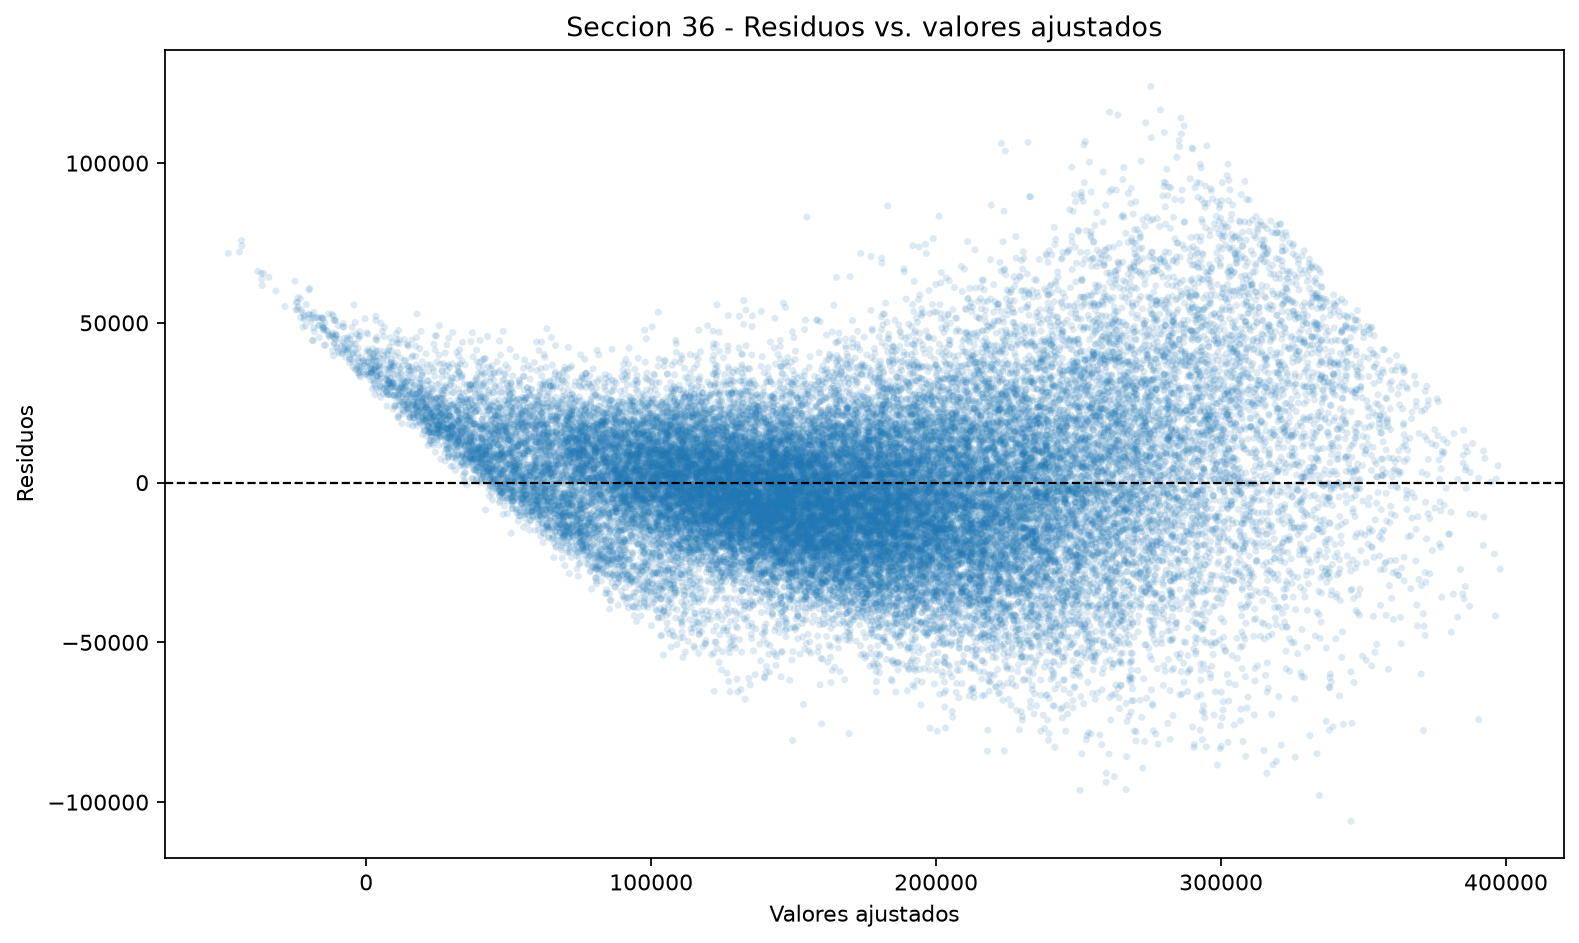

                        diagnostico  ...                   interpretacion
0                     Breusch-Pagan  ...  Evidencia de heterocedasticidad
1  White (variables numericas base)  ...  Evidencia de heterocedasticidad

[2 rows x 7 columns]
Figure(1000x600)
🏃 View run ols_temporal_seccion_36_diagnostico_heterocedasticidad at: http://127.0.0.1:5000/#/experiments/4/runs/01fd41c8f54d4bd69569d7165e45beb9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Filas de entrenamiento: 37502
Grafico guardado en: diagnosticos\residuos_vs_ajustados_seccion_36.png
                     diagnostico  estadistico_lm  p_value_lm  estadistico_f  p_value_f  rechazar_h0_05                  interpretacion
                   Breusch-Pagan     5572.592395         0.0      25.391855        0.0            True Evidencia de heterocedasticidad
White (variables numericas base)     4046.131965         0.0      38.314211        0.0            True Evidencia de heterocedasticidad


In [1]:
from pathlib import Path
import io

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

CORTE_TEMPORAL_SECCION_36 = "2025-01"
RUTA_MODELO_SECCION_36 = Path("data_sets_transformados/secondary_market_modelado_seccion_34.csv")
RUTA_GRAFICO_SECCION_36 = Path("diagnosticos/residuos_vs_ajustados_seccion_36.png")
ALFA_SECCION_36 = 0.05

VARIABLES_WHITE_SECCION_36 = [
    "lat",
    "lon",
    "living_area",
    "kitchen_area",
    "rooms",
    "floor",
    "total_floors",
    "ceiling_height",
    "metro_distance_min",
    "to_center_km",
    "mortgage_rate_at_listing",
    "date_posted_year",
    "date_posted_month",
    "building_age",
]

df_seccion_36 = pd.read_csv(RUTA_MODELO_SECCION_36)
df_train_seccion_36 = df_seccion_36[
    df_seccion_36["periodo"] < CORTE_TEMPORAL_SECCION_36
].copy()

if df_train_seccion_36.empty:
    raise ValueError("El corte temporal no produjo datos de entrenamiento")

X_train_seccion_36 = df_train_seccion_36.drop(columns=["price_per_sqm", "periodo"])
y_train_seccion_36 = df_train_seccion_36["price_per_sqm"]
X_train_seccion_36_sm = sm.add_constant(X_train_seccion_36, has_constant="add")
modelo_seccion_36 = sm.OLS(y_train_seccion_36, X_train_seccion_36_sm).fit()
valores_ajustados_seccion_36 = modelo_seccion_36.fittedvalues
residuos_seccion_36 = modelo_seccion_36.resid

# Breusch-Pagan: diagnostico auxiliar usando todos los predictores del modelo.
bp_lm, bp_pvalue_lm, bp_f, bp_pvalue_f = het_breuschpagan(
    residuos_seccion_36, X_train_seccion_36_sm
)

# White: diagnostico auxiliar sobre las variables numericas base.
variables_white_faltantes = sorted(
    set(VARIABLES_WHITE_SECCION_36) - set(X_train_seccion_36.columns)
)
if variables_white_faltantes:
    raise KeyError(f"Faltan variables para el test de White: {variables_white_faltantes}")
X_white_seccion_36 = sm.add_constant(
    X_train_seccion_36[VARIABLES_WHITE_SECCION_36], has_constant="add"
)
white_lm, white_pvalue_lm, white_f, white_pvalue_f = het_white(
    residuos_seccion_36, X_white_seccion_36
)

tabla_diagnosticos_seccion_36 = pd.DataFrame([
    {
        "diagnostico": "Breusch-Pagan",
        "estadistico_lm": float(bp_lm),
        "p_value_lm": float(bp_pvalue_lm),
        "estadistico_f": float(bp_f),
        "p_value_f": float(bp_pvalue_f),
        "rechazar_h0_05": bool(bp_pvalue_f < ALFA_SECCION_36),
    },
    {
        "diagnostico": "White (variables numericas base)",
        "estadistico_lm": float(white_lm),
        "p_value_lm": float(white_pvalue_lm),
        "estadistico_f": float(white_f),
        "p_value_f": float(white_pvalue_f),
        "rechazar_h0_05": bool(white_pvalue_f < ALFA_SECCION_36),
    },
])

def interpretar_diagnostico(p_value):
    return "Evidencia de heterocedasticidad" if p_value < ALFA_SECCION_36 else "No se rechaza homocedasticidad"

tabla_diagnosticos_seccion_36["interpretacion"] = tabla_diagnosticos_seccion_36["p_value_f"].map(
    interpretar_diagnostico
)

grafica_residuos_ajustados_seccion_36, eje_residuos_ajustados_seccion_36 = plt.subplots(
    figsize=(10, 6)
)
eje_residuos_ajustados_seccion_36.scatter(
    valores_ajustados_seccion_36,
    residuos_seccion_36,
    alpha=0.15,
    s=10,
    edgecolors="none",
)
eje_residuos_ajustados_seccion_36.axhline(
    0, color="black", linestyle="--", linewidth=1
)
eje_residuos_ajustados_seccion_36.set_title(
    "Seccion 36 - Residuos vs. valores ajustados"
)
eje_residuos_ajustados_seccion_36.set_xlabel("Valores ajustados")
eje_residuos_ajustados_seccion_36.set_ylabel("Residuos")
grafica_residuos_ajustados_seccion_36.tight_layout()
RUTA_GRAFICO_SECCION_36.parent.mkdir(parents=True, exist_ok=True)
grafica_residuos_ajustados_seccion_36.savefig(
    RUTA_GRAFICO_SECCION_36, dpi=160, bbox_inches="tight"
)

display(tabla_diagnosticos_seccion_36)
display(grafica_residuos_ajustados_seccion_36)

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_36_diagnostico_heterocedasticidad"):
    mlflow.set_tag("run_modelo_base_id", "9472e773307a445e991ed9c2f9fb5cda")
    mlflow.log_params({
        "seccion": 36,
        "modelo_base": "seccion_34_sin_total_area",
        "dataset": str(RUTA_MODELO_SECCION_36),
        "objetivo": "price_per_sqm",
        "corte_temporal": CORTE_TEMPORAL_SECCION_36,
        "filas_entrenamiento": len(df_train_seccion_36),
        "n_predictores_breusch_pagan": X_train_seccion_36.shape[1],
        "n_predictores_white": len(VARIABLES_WHITE_SECCION_36),
        "variables_white": ",".join(VARIABLES_WHITE_SECCION_36),
        "alfa": ALFA_SECCION_36,
    })
    mlflow.log_metrics({
        "breusch_pagan_lm": float(bp_lm),
        "breusch_pagan_pvalue_lm": float(bp_pvalue_lm),
        "breusch_pagan_f": float(bp_f),
        "breusch_pagan_pvalue_f": float(bp_pvalue_f),
        "white_lm": float(white_lm),
        "white_pvalue_lm": float(white_pvalue_lm),
        "white_f": float(white_f),
        "white_pvalue_f": float(white_pvalue_f),
    })
    mlflow.log_table(
        tabla_diagnosticos_seccion_36,
        artifact_file="diagnostico/tabla_heterocedasticidad_seccion_36.json",
    )
    mlflow.log_artifact(
        str(RUTA_GRAFICO_SECCION_36), artifact_path="diagnostico"
    )
    mlflow.log_text(
        "Modelo base: seccion 34 sin total_area\n"
        "Breusch-Pagan: matriz completa de predictores\n"
        "White: variables numericas base para evitar expansion combinatoria de dummies\n\n"
        + tabla_diagnosticos_seccion_36.to_string(index=False),
        "diagnostico/resumen_heterocedasticidad_seccion_36.txt",
    )

print(f"Filas de entrenamiento: {len(df_train_seccion_36)}")
print(f"Grafico guardado en: {RUTA_GRAFICO_SECCION_36}")
print(tabla_diagnosticos_seccion_36.to_string(index=False))


### Interpretacion de la seccion 36

El grafico muestra una dispersion cada vez mayor de los residuos a medida que aumentan los valores ajustados, con una forma de abanico. Esto es compatible visualmente con heterocedasticidad.

Los resultados formales tambien apuntan en esa direccion:

- **Breusch-Pagan**: estadistico F = `25,3919`, p-value < `0,001`.
- **White** sobre las variables numericas base: estadistico F = `38,3142`, p-value < `0,001`.

En ambos casos se rechaza la hipotesis nula de varianza constante al nivel del `5%`. Por lo tanto, los errores estandar y p-values del OLS convencional deben interpretarse con cautela. La siguiente alternativa metodologica sera evaluar errores estandar robustos HC3 y/o una transformacion logaritmica del objetivo, sin cambiar todavia el corte temporal ni la poblacion de evaluacion.

## 37. Analisis de multicolinealidad con VIF y TOL

Esta seccion analiza el modelo de la seccion 34, que elimina `total_area` y mantiene `living_area`. El objetivo es estudiar si algunos predictores contienen informacion demasiado parecida entre si.

La multicolinealidad no necesariamente empeora las predicciones, pero puede volver inestables los coeficientes individuales, aumentar sus errores estandar y dificultar la interpretacion de los p-values.

- **VIF (Variance Inflation Factor)** mide cuanto se infla la varianza estimada de un coeficiente por su relacion con los demas predictores.
- **TOL (Tolerance)** es el inverso del VIF: `TOL = 1 / VIF`.
- Segun los apuntes: `VIF = 1` indica ausencia de colinealidad; entre `1` y `5` indica cierta colinealidad; entre `5` y `10` es una se?al de alarma.

El calculo principal se realiza sobre las variables numericas base. Las variables categoricas codificadas como dummies se revisan aparte para detectar la trampa de las dummies.

In [1]:
from pathlib import Path
import mlflow
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.outliers_influence import variance_inflation_factor

CORTE_TEMPORAL_SECCION_37 = "2025-01"
RUTA_MODELO_SECCION_37 = Path("data_sets_transformados/secondary_market_modelado_seccion_34.csv")
RUTA_DATOS_CRUDOS_SECCION_37 = Path("data_sets/secondary_market.csv")
VARIABLES_NUMERICAS_BASE_SECCION_37 = [
    "lat", "lon", "living_area", "kitchen_area", "rooms", "floor",
    "total_floors", "ceiling_height", "metro_distance_min", "to_center_km",
    "mortgage_rate_at_listing", "date_posted_year", "date_posted_month", "building_age",
]
GRUPOS_DUMMY_SECCION_37 = {
    "district": "district_", "building_type": "building_type_", "has_balcony": "has_balcony_",
    "renovation": "renovation_", "metro_station": "metro_station_",
    "metro_distance_type": "metro_distance_type_", "seller_type": "seller_type_",
}

df_seccion_37 = pd.read_csv(RUTA_MODELO_SECCION_37)
df_train_seccion_37 = df_seccion_37[df_seccion_37["periodo"] < CORTE_TEMPORAL_SECCION_37].copy()
X_vif_seccion_37 = sm.add_constant(df_train_seccion_37[VARIABLES_NUMERICAS_BASE_SECCION_37].astype(float), has_constant="add")
filas_vif_seccion_37 = []
for i, variable in enumerate(X_vif_seccion_37.columns):
    if variable == "const": continue
    vif = float(variance_inflation_factor(X_vif_seccion_37.values, i))
    filas_vif_seccion_37.append({
        "variable": variable, "vif": vif, "tol": float(1 / vif),
        "interpretacion": "Colinealidad severa" if vif >= 10 else ("Senal de alarma" if vif >= 5 else "Colinealidad no preocupante"),
    })
tabla_vif_tol_seccion_37 = pd.DataFrame(filas_vif_seccion_37).sort_values("vif", ascending=False).reset_index(drop=True)

df_crudo_seccion_37 = pd.read_csv(RUTA_DATOS_CRUDOS_SECCION_37)
MAPEO_DUMMIES_SECCION_37 = {
    "district": "district_",
    "building_type": "building_type_",
    "renovation": "renovation_",
    "metro_station": "metro_station_",
    "has_balcony": "has_balcony_",
    "metro_distance_type": "metro_distance_type_",
    "seller_type": "seller_type_",
}
filas_dummies_seccion_37 = []
for variable_cruda, prefijo in MAPEO_DUMMIES_SECCION_37.items():
    columnas = [c for c in df_train_seccion_37.columns if c.startswith(prefijo)]
    valores_crudos = set(df_crudo_seccion_37[variable_cruda].astype(str).unique())
    valores_codificados = {c[len(prefijo):] for c in columnas}
    categorias_referencia = sorted(valores_crudos - valores_codificados)
    suma = df_train_seccion_37[columnas].sum(axis=1)
    filas_dummies_seccion_37.append({
        "grupo": variable_cruda,
        "n_categorias_crudas": len(valores_crudos),
        "n_dummies": len(columnas),
        "categorias_referencia_omitidas": ", ".join(categorias_referencia),
        "filas_con_dummies_en_cero": int((suma == 0).sum()),
        "porcentaje_filas_referencia": float((suma == 0).mean() * 100),
    })
tabla_dummies_seccion_37 = pd.DataFrame(filas_dummies_seccion_37)

display(tabla_vif_tol_seccion_37)
display(tabla_dummies_seccion_37)

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_37_vif_tol_referencia"):
    mlflow.set_tag("run_modelo_base_id", "9472e773307a445e991ed9c2f9fb5cda")
    mlflow.log_params({"seccion":37,"modelo_base":"seccion_34_sin_total_area","dataset":str(RUTA_MODELO_SECCION_37),"objetivo":"price_per_sqm","corte_temporal":CORTE_TEMPORAL_SECCION_37,"filas_entrenamiento":len(df_train_seccion_37),"n_variables_vif":len(VARIABLES_NUMERICAS_BASE_SECCION_37),"criterio_vif_alarma":"VIF >= 5","criterio_vif_severo":"VIF >= 10"})
    mlflow.log_metrics({"vif_maximo":float(tabla_vif_tol_seccion_37.vif.max()),"vif_to_center_km":float(tabla_vif_tol_seccion_37.loc[tabla_vif_tol_seccion_37.variable=="to_center_km","vif"].iloc[0]),"vif_metro_distance_min":float(tabla_vif_tol_seccion_37.loc[tabla_vif_tol_seccion_37.variable=="metro_distance_min","vif"].iloc[0]),"n_variables_vif_alarma":float((tabla_vif_tol_seccion_37.vif>=5).sum()),"n_grupos_dummy_revisados":float(len(tabla_dummies_seccion_37))})
    mlflow.log_table(tabla_vif_tol_seccion_37, artifact_file="diagnostico/tabla_vif_tol_seccion_37.json")
    mlflow.log_table(tabla_dummies_seccion_37, artifact_file="diagnostico/tabla_dummies_seccion_37.json")
    mlflow.log_text(tabla_vif_tol_seccion_37.to_string(index=False)+"\n\n"+tabla_dummies_seccion_37.to_string(index=False), "diagnostico/resumen_vif_tol_seccion_37.txt")

print("Filas de entrenamiento:",len(df_train_seccion_37))
print(tabla_vif_tol_seccion_37[tabla_vif_tol_seccion_37.vif>=5].to_string(index=False))
print(tabla_dummies_seccion_37.to_string(index=False))


variable,vif,tol,interpretacion
to_center_km,7.791802,0.128340,Senal de alarma
metro_distance_min,5.338881,0.187305,Senal de alarma
rooms,4.158100,0.240494,Colinealidad no preocupante
living_area,3.763319,0.265723,Colinealidad no preocupante
date_posted_year,2.525459,0.395968,Colinealidad no preocupante
mortgage_rate_at_listing,2.522367,0.396453,Colinealidad no preocupante
lon,2.068188,0.483515,Colinealidad no preocupante
lat,2.045022,0.488992,Colinealidad no preocupante
floor,1.528093,0.654411,Colinealidad no preocupante
total_floors,1.527931,0.654480,Colinealidad no preocupante


grupo,n_categorias_crudas,n_dummies,categorias_referencia_omitidas,filas_con_dummies_en_cero,porcentaje_filas_referencia
district,129,128,Aeroport,301,0.802624
building_type,6,5,brick,6589,17.569730
renovation,4,3,cosmetic,15205,40.544504
metro_station,104,103,Aleksandrovsky Sad,266,0.709296
has_balcony,2,1,False,9415,25.105328
metro_distance_type,2,1,transport,30655,81.742307
seller_type,2,1,agency,24587,65.561837


                    variable       vif       tol               interpretacion
0               to_center_km  7.791802  0.128340              Senal de alarma
1         metro_distance_min  5.338881  0.187305              Senal de alarma
2                      rooms  4.158100  0.240494  Colinealidad no preocupante
3                living_area  3.763319  0.265723  Colinealidad no preocupante
4           date_posted_year  2.525459  0.395968  Colinealidad no preocupante
5   mortgage_rate_at_listing  2.522367  0.396453  Colinealidad no preocupante
6                        lon  2.068188  0.483515  Colinealidad no preocupante
7                        lat  2.045022  0.488992  Colinealidad no preocupante
8                      floor  1.528093  0.654411  Colinealidad no preocupante
9               total_floors  1.527931  0.654480  Colinealidad no preocupante
10              kitchen_area  1.394180  0.717268  Colinealidad no preocupante
11              building_age  1.074830  0.930380  Colinealidad n

### Interpretacion detallada de la seccion 37

#### 1. Variables numericas

- `to_center_km`: VIF aproximadamente `7,79`, TOL aproximadamente `0,128`. Es una se?al de alarma y comparte informacion con otras variables de ubicacion.
- `metro_distance_min`: VIF aproximadamente `5,34`, TOL aproximadamente `0,187`. Tambien supera el umbral de alarma.
- `rooms`: VIF aproximadamente `4,16`, TOL aproximadamente `0,240`. Presenta cierta colinealidad, pero no alcanza el umbral de alarma.
- `living_area`: VIF aproximadamente `3,76`, TOL aproximadamente `0,266`. Tiene relacion con otras variables de superficie, aunque eliminar `total_area` redujo la redundancia directa.
- El resto de las variables numericas presenta VIF menor que `3`.

#### 2. Categorias de referencia

El dataset no contiene valores faltantes: las tres versiones revisadas tienen cero valores `NaN`. Las filas que tienen todas las dummies de un grupo en cero representan la categoria de referencia omitida durante el one-hot encoding.

Las categorias de referencia identificadas son:

- `district`: `Aeroport`.
- `building_type`: `brick`.
- `renovation`: `cosmetic`.
- `metro_station`: `Aleksandrovsky Sad`.
- `has_balcony`: `False`.
- `metro_distance_type`: `transport`.
- `seller_type`: `agency`.

Por ejemplo, una vivienda del distrito `Aeroport` tiene todas las columnas `district_*` en cero porque `Aeroport` funciona como categoria de referencia. Esto no es un dato faltante.

#### 3. ?Para que sirven VIF y TOL?

- VIF muestra cuanto puede inflarse la varianza de un coeficiente por la informacion repetida entre predictores.
- TOL muestra cuanta informacion propia conserva una variable despues de considerar las demas.
- Sirven para evaluar estabilidad e interpretabilidad de coeficientes y p-values.
- No demuestran por si solos que el modelo prediga mal; por eso no se eliminan variables automaticamente.

#### Conclusion

La colinealidad mas relevante se concentra en `to_center_km` y `metro_distance_min`. `living_area` presenta una relacion moderada, pero no preocupante segun el umbral de los apuntes. La codificacion dummy ya utiliza categorias de referencia; por lo tanto, no hace falta crear una categoria `missing` ni volver a eliminar dummies por este motivo.

## 38. Comparación OLS, Ridge, Lasso y PCR

Se comparan cuatro modelos sobre el dataset de la sección 34, sin transformar el objetivo `price_per_sqm`:

- **OLS** como referencia estadística.
- **Ridge** para controlar la varianza manteniendo todos los predictores.
- **Lasso** para evaluar si algunos coeficientes se aproximan a cero.
- **PCR** para reducir la dimensionalidad mediante componentes principales y luego ajustar Ridge.

Todos los modelos utilizan exactamente los mismos registros de entrenamiento y prueba definidos por el corte temporal `2025-01`. La estandarización, la PCA y la selección de hiperparámetros se ajustan dentro de pipelines usando únicamente los datos de entrenamiento. Para la validación interna se usa `TimeSeriesSplit`, sin mezclar observaciones futuras con pasadas.

Las métricas se calculan en la escala original de `price_per_sqm` y se registran en MLflow.

In [1]:
from pathlib import Path

import mlflow
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.linear_model import LassoCV, Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

CORTE_TEMPORAL_SECCION_38 = "2025-01"
RUTA_MODELO_SECCION_38 = Path("data_sets_transformados/secondary_market_modelado_seccion_34.csv")
ALPHAS_SECCION_38 = np.logspace(-4, 4, 25)
ALPHAS_LASSO_SECCION_38 = np.logspace(-5, 2, 25)
N_SPLITS_CV_SECCION_38 = 5

df_seccion_38 = pd.read_csv(RUTA_MODELO_SECCION_38).sort_values("periodo").reset_index(drop=True)
df_train_seccion_38 = df_seccion_38[df_seccion_38["periodo"] < CORTE_TEMPORAL_SECCION_38].copy()
df_test_seccion_38 = df_seccion_38[df_seccion_38["periodo"] >= CORTE_TEMPORAL_SECCION_38].copy()
if df_train_seccion_38.empty or df_test_seccion_38.empty:
    raise ValueError("El corte temporal no produjo train y test válidos")

X_train_seccion_38 = df_train_seccion_38.drop(columns=["price_per_sqm", "periodo"])
X_test_seccion_38 = df_test_seccion_38.drop(columns=["price_per_sqm", "periodo"])
y_train_seccion_38 = df_train_seccion_38["price_per_sqm"]
y_test_seccion_38 = df_test_seccion_38["price_per_sqm"]
if (y_train_seccion_38 <= 0).any() or (y_test_seccion_38 <= 0).any():
    raise ValueError("price_per_sqm debe ser positivo para calcular MAPE")

cv_temporal_seccion_38 = TimeSeriesSplit(n_splits=N_SPLITS_CV_SECCION_38)
def calcular_metricas_seccion_38(y_real, predicciones, conjunto):
    y_real_np = y_real.to_numpy()
    return {
        f"mae_{conjunto}": float(mean_absolute_error(y_real, predicciones)),
        f"rmse_{conjunto}": float(mean_squared_error(y_real, predicciones) ** 0.5),
        f"r2_{conjunto}": float(r2_score(y_real, predicciones)),
        f"mape_{conjunto}": float(np.mean(np.abs((y_real_np - predicciones) / y_real_np)) * 100),
    }

modelo_ols_seccion_38 = sm.OLS(y_train_seccion_38, sm.add_constant(X_train_seccion_38, has_constant="add")).fit()
pred_ols_train_seccion_38 = modelo_ols_seccion_38.predict(sm.add_constant(X_train_seccion_38, has_constant="add"))
pred_ols_test_seccion_38 = modelo_ols_seccion_38.predict(sm.add_constant(X_test_seccion_38, has_constant="add"))

modelo_ridge_seccion_38 = Pipeline([
    ("standard_scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=ALPHAS_SECCION_38, cv=cv_temporal_seccion_38, scoring="neg_root_mean_squared_error")),
])
modelo_ridge_seccion_38.fit(X_train_seccion_38, y_train_seccion_38)
pred_ridge_train_seccion_38 = modelo_ridge_seccion_38.predict(X_train_seccion_38)
pred_ridge_test_seccion_38 = modelo_ridge_seccion_38.predict(X_test_seccion_38)

modelo_lasso_seccion_38 = Pipeline([
    ("standard_scaler", StandardScaler()),
    ("lasso", LassoCV(alphas=ALPHAS_LASSO_SECCION_38, cv=cv_temporal_seccion_38, max_iter=20000, tol=1e-4, n_jobs=-1)),
])
modelo_lasso_seccion_38.fit(X_train_seccion_38, y_train_seccion_38)
pred_lasso_train_seccion_38 = modelo_lasso_seccion_38.predict(X_train_seccion_38)
pred_lasso_test_seccion_38 = modelo_lasso_seccion_38.predict(X_test_seccion_38)

modelo_pcr_seccion_38 = GridSearchCV(
    Pipeline([
        ("standard_scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, svd_solver="full")),
        ("ridge", Ridge()),
    ]),
    param_grid={"ridge__alpha": ALPHAS_SECCION_38},
    cv=cv_temporal_seccion_38,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
modelo_pcr_seccion_38.fit(X_train_seccion_38, y_train_seccion_38)
pred_pcr_train_seccion_38 = modelo_pcr_seccion_38.predict(X_train_seccion_38)
pred_pcr_test_seccion_38 = modelo_pcr_seccion_38.predict(X_test_seccion_38)

predicciones_seccion_38 = {
    "OLS": (pred_ols_train_seccion_38, pred_ols_test_seccion_38),
    "Ridge": (pred_ridge_train_seccion_38, pred_ridge_test_seccion_38),
    "Lasso": (pred_lasso_train_seccion_38, pred_lasso_test_seccion_38),
    "PCR": (pred_pcr_train_seccion_38, pred_pcr_test_seccion_38),
}
filas_comparacion_seccion_38 = []
for nombre_modelo, (pred_train, pred_test) in predicciones_seccion_38.items():
    fila = {"modelo": nombre_modelo}
    fila.update(calcular_metricas_seccion_38(y_train_seccion_38, pred_train, "train"))
    fila.update(calcular_metricas_seccion_38(y_test_seccion_38, pred_test, "test"))
    filas_comparacion_seccion_38.append(fila)
comparacion_modelos_seccion_38 = pd.DataFrame(filas_comparacion_seccion_38)

parametros_modelos_seccion_38 = pd.DataFrame([
    {"modelo": "OLS", "hiperparametro": "ninguno", "valor": None, "detalle": "statsmodels OLS con constante"},
    {"modelo": "Ridge", "hiperparametro": "alpha", "valor": float(modelo_ridge_seccion_38.named_steps["ridge"].alpha_), "detalle": "StandardScaler + RidgeCV + TimeSeriesSplit"},
    {"modelo": "Lasso", "hiperparametro": "alpha", "valor": float(modelo_lasso_seccion_38.named_steps["lasso"].alpha_), "detalle": "StandardScaler + LassoCV + TimeSeriesSplit"},
    {"modelo": "PCR", "hiperparametro": "alpha", "valor": float(modelo_pcr_seccion_38.best_params_["ridge__alpha"]), "detalle": f"StandardScaler + PCA 95% + Ridge; componentes={modelo_pcr_seccion_38.best_estimator_.named_steps['pca'].n_components_}"},
])
coeficientes_ols_seccion_38 = pd.DataFrame({"variable": modelo_ols_seccion_38.params.index, "coeficiente": modelo_ols_seccion_38.params.to_numpy(), "p_value": modelo_ols_seccion_38.pvalues.to_numpy(), "significativa_0_05": modelo_ols_seccion_38.pvalues.to_numpy() <= 0.05})
coeficientes_lasso_seccion_38 = pd.DataFrame({"variable": X_train_seccion_38.columns, "coeficiente_estandarizado": modelo_lasso_seccion_38.named_steps["lasso"].coef_})
coeficientes_lasso_seccion_38["coeficiente_cero"] = coeficientes_lasso_seccion_38["coeficiente_estandarizado"] == 0
residuos_test_modelos_seccion_38 = pd.DataFrame({"periodo": df_test_seccion_38["periodo"].to_numpy(), "real": y_test_seccion_38.to_numpy()})
for nombre_modelo, (_, pred_test) in predicciones_seccion_38.items():
    residuos_test_modelos_seccion_38[f"prediccion_{nombre_modelo.lower()}"] = pred_test
    residuos_test_modelos_seccion_38[f"residuo_{nombre_modelo.lower()}"] = y_test_seccion_38.to_numpy() - pred_test

display(comparacion_modelos_seccion_38)
display(parametros_modelos_seccion_38)

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_38_comparacion_modelos"):
    mlflow.set_tag("run_modelo_base_id", "9472e773307a445e991ed9c2f9fb5cda")
    mlflow.log_params({"seccion": 38, "dataset": str(RUTA_MODELO_SECCION_38), "objetivo": "price_per_sqm", "objetivo_transformado": False, "corte_temporal": CORTE_TEMPORAL_SECCION_38, "filas_entrenamiento": len(df_train_seccion_38), "filas_prueba": len(df_test_seccion_38), "n_predictores": X_train_seccion_38.shape[1], "cv_tipo": "TimeSeriesSplit", "cv_folds": N_SPLITS_CV_SECCION_38, "pca_varianza_objetivo": 0.95, "ridge_alpha": float(modelo_ridge_seccion_38.named_steps["ridge"].alpha_), "lasso_alpha": float(modelo_lasso_seccion_38.named_steps["lasso"].alpha_), "lasso_coeficientes_no_cero": int(np.count_nonzero(modelo_lasso_seccion_38.named_steps["lasso"].coef_)), "pcr_alpha": float(modelo_pcr_seccion_38.best_params_["ridge__alpha"]), "pcr_n_componentes": int(modelo_pcr_seccion_38.best_estimator_.named_steps["pca"].n_components_)})
    metricas = {}
    for _, fila in comparacion_modelos_seccion_38.iterrows():
        nombre = fila["modelo"].lower()
        for metrica in ["mae_test", "rmse_test", "r2_test", "mape_test", "mae_train", "rmse_train", "r2_train", "mape_train"]:
            metricas[f"{nombre}_{metrica}"] = float(fila[metrica])
    mlflow.log_metrics(metricas)
    mlflow.log_table(comparacion_modelos_seccion_38, artifact_file="comparacion/comparacion_modelos_seccion_38.json")
    mlflow.log_table(parametros_modelos_seccion_38, artifact_file="comparacion/parametros_modelos_seccion_38.json")
    mlflow.log_table(coeficientes_ols_seccion_38, artifact_file="modelo/coeficientes_ols_seccion_38.json")
    mlflow.log_table(coeficientes_lasso_seccion_38, artifact_file="modelo/coeficientes_lasso_seccion_38.json")
    mlflow.log_table(residuos_test_modelos_seccion_38, artifact_file="diagnostico/residuos_test_modelos_seccion_38.json")
    mlflow.log_text(modelo_ols_seccion_38.summary().as_text(), "modelo/resumen_ols_seccion_38.txt")

print(f"Filas de entrenamiento: {len(df_train_seccion_38)}")
print(f"Filas de prueba: {len(df_test_seccion_38)}")
print(comparacion_modelos_seccion_38.to_string(index=False))
print(parametros_modelos_seccion_38.to_string(index=False))


modelo,mae_train,rmse_train,r2_train,mape_train,mae_test,rmse_test,r2_test,mape_test
OLS,18301.594004,23995.142718,0.906786,12.878020,29090.093697,34121.642823,0.818602,20.273061
Ridge,18301.593993,23995.142718,0.906786,12.878020,29090.093618,34121.642736,0.818602,20.273061
Lasso,18301.594003,23995.142718,0.906786,12.878020,29090.093674,34121.642799,0.818602,20.273061
PCR,23099.460578,30034.116388,0.853963,15.882215,28097.262734,34176.902873,0.818014,18.731243


modelo,hiperparametro,valor,detalle
OLS,ninguno,NaN,statsmodels OLS con constante
Ridge,alpha,0.00010,StandardScaler + RidgeCV + TimeSeriesSplit
Lasso,alpha,0.00001,StandardScaler + LassoCV + TimeSeriesSplit
PCR,alpha,100.00000,StandardScaler + PCA 95% + Ridge; componentes=224


  modelo     mae_train    rmse_train  ...     rmse_test   r2_test  mape_test
0    OLS  18301.594004  23995.142718  ...  34121.642823  0.818602  20.273061
1  Ridge  18301.593993  23995.142718  ...  34121.642736  0.818602  20.273061
2  Lasso  18301.594003  23995.142718  ...  34121.642799  0.818602  20.273061
3    PCR  23099.460578  30034.116388  ...  34176.902873  0.818014  18.731243

[4 rows x 9 columns]
  modelo  ...                                            detalle
0    OLS  ...                      statsmodels OLS con constante
1  Ridge  ...         StandardScaler + RidgeCV + TimeSeriesSplit
2  Lasso  ...         StandardScaler + LassoCV + TimeSeriesSplit
3    PCR  ...  StandardScaler + PCA 95% + Ridge; componentes=224

[4 rows x 4 columns]
🏃 View run ols_temporal_seccion_38_comparacion_modelos at: http://127.0.0.1:5000/#/experiments/4/runs/7a09c0858696498d9c9349a1855b2c73
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Filas de entrenamiento: 37502
Filas de prueba: 9550

### Interpretación de la sección 38

La comparación se realiza sobre la misma prueba temporal y en la escala original de `price_per_sqm`.

- **OLS** queda como referencia estadística.
- **Ridge** controla la magnitud de los coeficientes, pero no elimina variables.
- **Lasso** puede llevar coeficientes a cero y producir una selección automática.
- **PCR** reemplaza los predictores originales por componentes principales; puede reducir la colinealidad, pero dificulta interpretar cada variable.

La decisión no se toma por una sola métrica: se comparan MAE, RMSE, R² y MAPE. Si Ridge queda prácticamente igual que OLS, la regularización no agrega una mejora predictiva relevante. Si Lasso deja casi todos los coeficientes distintos de cero, tampoco está simplificando realmente el modelo. Si PCR mejora la colinealidad pero empeora RMSE o R², se conserva como referencia metodológica y no como modelo principal.

## 39. Variante OLS sin `metro_distance_min`

Esta variante parte del dataset de la sección 34 y elimina únicamente `metro_distance_min`, una variable con VIF elevado (`5,34`). No se eliminan filas ni otras variables.

La evaluación conserva el corte temporal `2025-01` y compara la variante contra la sección 34 utilizando exactamente los mismos registros de prueba. Además de las métricas predictivas, se recalculan VIF/TOL sobre las variables numéricas para verificar si disminuye la colinealidad.

La corrida y los artefactos se registran en MLflow para decidir si la eliminación está justificada.

In [1]:
from pathlib import Path

import mlflow
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

CORTE_TEMPORAL_SECCION_39 = "2025-01"
VARIABLE_ELIMINADA_SECCION_39 = "metro_distance_min"
RUTA_ORIGEN_SECCION_39 = Path("data_sets_transformados/secondary_market_modelado_seccion_34.csv")
RUTA_SALIDA_SECCION_39 = Path("data_sets_transformados/secondary_market_modelado_seccion_39.csv")
VARIABLES_NUMERICAS_SECCION_39 = [
    "lat", "lon", "living_area", "kitchen_area", "rooms", "floor",
    "total_floors", "ceiling_height", "metro_distance_min", "to_center_km",
    "mortgage_rate_at_listing", "date_posted_year", "date_posted_month", "building_age",
]

origen_seccion_39 = pd.read_csv(RUTA_ORIGEN_SECCION_39)
if VARIABLE_ELIMINADA_SECCION_39 not in origen_seccion_39.columns:
    raise KeyError(f"No se encontró la columna esperada: {VARIABLE_ELIMINADA_SECCION_39}")
if origen_seccion_39["price_per_sqm"].isna().any() or (origen_seccion_39["price_per_sqm"] <= 0).any():
    raise ValueError("price_per_sqm contiene valores faltantes, cero o negativos")

variante_seccion_39 = origen_seccion_39.drop(columns=[VARIABLE_ELIMINADA_SECCION_39]).copy()
variante_seccion_39.to_csv(RUTA_SALIDA_SECCION_39, index=False)

train_origen_seccion_39 = origen_seccion_39[origen_seccion_39["periodo"] < CORTE_TEMPORAL_SECCION_39].copy()
test_origen_seccion_39 = origen_seccion_39[origen_seccion_39["periodo"] >= CORTE_TEMPORAL_SECCION_39].copy()
train_variante_seccion_39 = variante_seccion_39[variante_seccion_39["periodo"] < CORTE_TEMPORAL_SECCION_39].copy()
test_variante_seccion_39 = variante_seccion_39[variante_seccion_39["periodo"] >= CORTE_TEMPORAL_SECCION_39].copy()
if len(test_origen_seccion_39) != len(test_variante_seccion_39):
    raise ValueError("La eliminación de la variable modificó la cantidad de registros de prueba")
if not test_origen_seccion_39["price_per_sqm"].reset_index(drop=True).equals(test_variante_seccion_39["price_per_sqm"].reset_index(drop=True)):
    raise ValueError("La variante no conserva exactamente el mismo objetivo de prueba")

X_train_origen_seccion_39 = train_origen_seccion_39.drop(columns=["price_per_sqm", "periodo"])
X_test_origen_seccion_39 = test_origen_seccion_39.drop(columns=["price_per_sqm", "periodo"])
X_train_variante_seccion_39 = train_variante_seccion_39.drop(columns=["price_per_sqm", "periodo"])
X_test_variante_seccion_39 = test_variante_seccion_39.drop(columns=["price_per_sqm", "periodo"])
y_train_seccion_39 = train_origen_seccion_39["price_per_sqm"]
y_test_seccion_39 = test_origen_seccion_39["price_per_sqm"]

def metricas_seccion_39(y_real, predicciones, conjunto):
    y_real_np = y_real.to_numpy()
    return {
        f"mae_{conjunto}": float(mean_absolute_error(y_real, predicciones)),
        f"rmse_{conjunto}": float(mean_squared_error(y_real, predicciones) ** 0.5),
        f"r2_{conjunto}": float(r2_score(y_real, predicciones)),
        f"mape_{conjunto}": float(np.mean(np.abs((y_real_np - predicciones) / y_real_np)) * 100),
    }

modelo_origen_seccion_39 = sm.OLS(
    y_train_seccion_39,
    sm.add_constant(X_train_origen_seccion_39, has_constant="add"),
).fit()
modelo_variante_seccion_39 = sm.OLS(
    y_train_seccion_39,
    sm.add_constant(X_train_variante_seccion_39, has_constant="add"),
).fit()
pred_origen_train_seccion_39 = modelo_origen_seccion_39.predict(sm.add_constant(X_train_origen_seccion_39, has_constant="add"))
pred_origen_test_seccion_39 = modelo_origen_seccion_39.predict(sm.add_constant(X_test_origen_seccion_39, has_constant="add"))
pred_variante_train_seccion_39 = modelo_variante_seccion_39.predict(sm.add_constant(X_train_variante_seccion_39, has_constant="add"))
pred_variante_test_seccion_39 = modelo_variante_seccion_39.predict(sm.add_constant(X_test_variante_seccion_39, has_constant="add"))

comparacion_modelos_seccion_39 = pd.DataFrame([
    {
        "modelo": "Sección 34 - OLS completo",
        **metricas_seccion_39(y_train_seccion_39, pred_origen_train_seccion_39, "train"),
        **metricas_seccion_39(y_test_seccion_39, pred_origen_test_seccion_39, "test"),
        "aic": float(modelo_origen_seccion_39.aic),
        "bic": float(modelo_origen_seccion_39.bic),
        "condition_number": float(modelo_origen_seccion_39.condition_number),
    },
    {
        "modelo": "Sección 39 - sin metro_distance_min",
        **metricas_seccion_39(y_train_seccion_39, pred_variante_train_seccion_39, "train"),
        **metricas_seccion_39(y_test_seccion_39, pred_variante_test_seccion_39, "test"),
        "aic": float(modelo_variante_seccion_39.aic),
        "bic": float(modelo_variante_seccion_39.bic),
        "condition_number": float(modelo_variante_seccion_39.condition_number),
    },
])

def calcular_vif_seccion_39(df_train, etiqueta):
    variables = [v for v in VARIABLES_NUMERICAS_SECCION_39 if v in df_train.columns]
    matriz = sm.add_constant(df_train[variables].astype(float), has_constant="add")
    filas = []
    for i, variable in enumerate(matriz.columns):
        if variable == "const":
            continue
        vif = float(variance_inflation_factor(matriz.values, i))
        filas.append({
            "modelo": etiqueta,
            "variable": variable,
            "vif": vif,
            "tol": float(1 / vif),
            "alarma_vif_5": bool(vif >= 5),
        })
    return pd.DataFrame(filas)

vif_seccion_39 = pd.concat([
    calcular_vif_seccion_39(train_origen_seccion_39, "Sección 34"),
    calcular_vif_seccion_39(train_variante_seccion_39, "Sección 39"),
], ignore_index=True)

coeficientes_seccion_39 = pd.DataFrame({
    "variable": modelo_variante_seccion_39.params.index,
    "coeficiente": modelo_variante_seccion_39.params.to_numpy(),
    "p_value": modelo_variante_seccion_39.pvalues.to_numpy(),
    "significativa_0_05": modelo_variante_seccion_39.pvalues.to_numpy() <= 0.05,
})
residuos_test_seccion_39 = pd.DataFrame({
    "periodo": test_variante_seccion_39["periodo"].to_numpy(),
    "real": y_test_seccion_39.to_numpy(),
    "prediccion_seccion_34": pred_origen_test_seccion_39,
    "prediccion_seccion_39": pred_variante_test_seccion_39,
})
residuos_test_seccion_39["residuo_seccion_34"] = residuos_test_seccion_39["real"] - residuos_test_seccion_39["prediccion_seccion_34"]
residuos_test_seccion_39["residuo_seccion_39"] = residuos_test_seccion_39["real"] - residuos_test_seccion_39["prediccion_seccion_39"]

display(comparacion_modelos_seccion_39)
display(vif_seccion_39[vif_seccion_39["vif"] >= 5].sort_values(["modelo", "vif"], ascending=[True, False]))

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_39_sin_metro_distance_min"):
    mlflow.set_tag("run_modelo_base_id", "9472e773307a445e991ed9c2f9fb5cda")
    mlflow.set_tag("run_comparacion_seccion_38_id", "7a09c0858696498d9c9349a1855b2c73")
    mlflow.log_params({
        "seccion": 39,
        "modelo_base": "seccion_34_sin_total_area",
        "dataset_origen": str(RUTA_ORIGEN_SECCION_39),
        "dataset_salida": str(RUTA_SALIDA_SECCION_39),
        "variable_eliminada": VARIABLE_ELIMINADA_SECCION_39,
        "objetivo": "price_per_sqm",
        "corte_temporal": CORTE_TEMPORAL_SECCION_39,
        "filas_entrenamiento": len(train_variante_seccion_39),
        "filas_prueba": len(test_variante_seccion_39),
        "n_predictores_origen": X_train_origen_seccion_39.shape[1],
        "n_predictores_variante": X_train_variante_seccion_39.shape[1],
        "mismo_test": True,
        "criterio_vif_alarma": "VIF >= 5",
    })
    metricas_mlflow = {}
    for _, fila in comparacion_modelos_seccion_39.iterrows():
        nombre = "seccion34" if fila["modelo"].startswith("Sección 34") else "seccion39"
        for metrica in ["mae_test", "rmse_test", "r2_test", "mape_test", "mae_train", "rmse_train", "r2_train", "mape_train"]:
            metricas_mlflow[f"{nombre}_{metrica}"] = float(fila[metrica])
    metricas_mlflow["vif_maximo_seccion34"] = float(vif_seccion_39[vif_seccion_39["modelo"] == "Sección 34"]["vif"].max())
    metricas_mlflow["vif_maximo_seccion39"] = float(vif_seccion_39[vif_seccion_39["modelo"] == "Sección 39"]["vif"].max())
    metricas_mlflow["vif_to_center_km_seccion34"] = float(vif_seccion_39[(vif_seccion_39["modelo"] == "Sección 34") & (vif_seccion_39["variable"] == "to_center_km")]["vif"].iloc[0])
    metricas_mlflow["vif_to_center_km_seccion39"] = float(vif_seccion_39[(vif_seccion_39["modelo"] == "Sección 39") & (vif_seccion_39["variable"] == "to_center_km")]["vif"].iloc[0])
    mlflow.log_metrics(metricas_mlflow)
    mlflow.log_artifact(str(RUTA_SALIDA_SECCION_39), artifact_path="dataset")
    mlflow.log_table(comparacion_modelos_seccion_39, artifact_file="comparacion/comparacion_ols_seccion_34_vs_39.json")
    mlflow.log_table(vif_seccion_39, artifact_file="diagnostico/vif_tol_seccion_34_vs_39.json")
    mlflow.log_table(coeficientes_seccion_39, artifact_file="modelo/coeficientes_ols_seccion_39.json")
    mlflow.log_table(residuos_test_seccion_39, artifact_file="diagnostico/residuos_test_seccion_39.json")
    mlflow.log_text(modelo_variante_seccion_39.summary().as_text(), "modelo/resumen_ols_seccion_39.txt")

print("Filas de entrenamiento:", len(train_variante_seccion_39))
print("Filas de prueba:", len(test_variante_seccion_39))
print(comparacion_modelos_seccion_39.to_string(index=False))
print(vif_seccion_39[vif_seccion_39["vif"] >= 5].sort_values(["modelo", "vif"], ascending=[True, False]).to_string(index=False))


modelo,mae_train,rmse_train,r2_train,mape_train,mae_test,rmse_test,r2_test,mape_test,aic,bic,condition_number
Sección 34 - OLS completo,18301.594004,23995.142718,0.906786,12.878020,29090.093696,34121.642823,0.818602,20.273061,863400.910827,865593.673260,1.146035e+07
Sección 39 - sin metro_distance_min,18592.328642,24593.678556,0.902078,12.857654,29585.683758,34603.072128,0.813447,20.526747,865246.860696,867431.090979,1.145542e+07


modelo,variable,vif,tol,alarma_vif_5
Sección 34,to_center_km,7.791802,0.128340,True
Sección 34,metro_distance_min,5.338881,0.187305,True


                                modelo  ...  condition_number
0            Sección 34 - OLS completo  ...      1.146035e+07
1  Sección 39 - sin metro_distance_min  ...      1.145542e+07

[2 rows x 12 columns]
       modelo            variable       vif       tol  alarma_vif_5
9  Sección 34        to_center_km  7.791802  0.128340          True
8  Sección 34  metro_distance_min  5.338881  0.187305          True
🏃 View run ols_temporal_seccion_39_sin_metro_distance_min at: http://127.0.0.1:5000/#/experiments/4/runs/da4cd9285478459f85b3a31cef440cd6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Filas de entrenamiento: 37502
Filas de prueba: 9550
                             modelo    mae_train   rmse_train  r2_train  mape_train     mae_test    rmse_test  r2_test  mape_test           aic           bic  condition_number
          Sección 34 - OLS completo 18301.594004 23995.142718  0.906786   12.878020 29090.093696 34121.642823 0.818602  20.273061 863400.910827 865593.673260    

### Interpretación de la sección 39

Esta es una comparación controlada: solo cambia la eliminación de `metro_distance_min`; la población de evaluación, el objetivo y el corte temporal permanecen iguales.

La variable se conserva o se elimina según el balance entre:

- Mejora o deterioro de RMSE, MAE, MAPE y R².
- Reducción efectiva del VIF, especialmente de `to_center_km`.
- Cambios en AIC, BIC y número de predictores.

Una reducción del VIF no alcanza por sí sola para justificar eliminar la variable. Si la predicción empeora de forma relevante, se mantendrá `metro_distance_min` aunque presente colinealidad moderada.

## 40. Variante OLS sin `to_center_km`

Esta variante parte del dataset de la sección 34, mantiene `metro_distance_min` y elimina únicamente `to_center_km`, la variable numérica con mayor VIF (`7,79`). No se eliminan filas ni otras variables.

La evaluación conserva el corte temporal `2025-01` y compara la variante contra la sección 34 usando exactamente los mismos registros de prueba. También se recalculan VIF/TOL para comprobar si disminuye la colinealidad sin perder capacidad predictiva.

La corrida y sus artefactos se registran en MLflow.

In [1]:
from pathlib import Path

import mlflow
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

CORTE_TEMPORAL_SECCION_40 = "2025-01"
VARIABLE_ELIMINADA_SECCION_40 = "to_center_km"
RUTA_ORIGEN_SECCION_40 = Path("data_sets_transformados/secondary_market_modelado_seccion_34.csv")
RUTA_SALIDA_SECCION_40 = Path("data_sets_transformados/secondary_market_modelado_seccion_40.csv")
VARIABLES_NUMERICAS_SECCION_40 = [
    "lat", "lon", "living_area", "kitchen_area", "rooms", "floor",
    "total_floors", "ceiling_height", "metro_distance_min", "to_center_km",
    "mortgage_rate_at_listing", "date_posted_year", "date_posted_month", "building_age",
]

origen_seccion_40 = pd.read_csv(RUTA_ORIGEN_SECCION_40)
if VARIABLE_ELIMINADA_SECCION_40 not in origen_seccion_40.columns:
    raise KeyError(f"No se encontró la columna esperada: {VARIABLE_ELIMINADA_SECCION_40}")
if origen_seccion_40["price_per_sqm"].isna().any() or (origen_seccion_40["price_per_sqm"] <= 0).any():
    raise ValueError("price_per_sqm contiene valores faltantes, cero o negativos")

variante_seccion_40 = origen_seccion_40.drop(columns=[VARIABLE_ELIMINADA_SECCION_40]).copy()
variante_seccion_40.to_csv(RUTA_SALIDA_SECCION_40, index=False)

train_origen_seccion_40 = origen_seccion_40[origen_seccion_40["periodo"] < CORTE_TEMPORAL_SECCION_40].copy()
test_origen_seccion_40 = origen_seccion_40[origen_seccion_40["periodo"] >= CORTE_TEMPORAL_SECCION_40].copy()
train_variante_seccion_40 = variante_seccion_40[variante_seccion_40["periodo"] < CORTE_TEMPORAL_SECCION_40].copy()
test_variante_seccion_40 = variante_seccion_40[variante_seccion_40["periodo"] >= CORTE_TEMPORAL_SECCION_40].copy()
if len(test_origen_seccion_40) != len(test_variante_seccion_40):
    raise ValueError("La eliminación modificó la cantidad de registros de prueba")
if not test_origen_seccion_40["price_per_sqm"].reset_index(drop=True).equals(test_variante_seccion_40["price_per_sqm"].reset_index(drop=True)):
    raise ValueError("La variante no conserva exactamente el mismo objetivo de prueba")

X_train_origen_seccion_40 = train_origen_seccion_40.drop(columns=["price_per_sqm", "periodo"])
X_test_origen_seccion_40 = test_origen_seccion_40.drop(columns=["price_per_sqm", "periodo"])
X_train_variante_seccion_40 = train_variante_seccion_40.drop(columns=["price_per_sqm", "periodo"])
X_test_variante_seccion_40 = test_variante_seccion_40.drop(columns=["price_per_sqm", "periodo"])
y_train_seccion_40 = train_origen_seccion_40["price_per_sqm"]
y_test_seccion_40 = test_origen_seccion_40["price_per_sqm"]

def metricas_seccion_40(y_real, predicciones, conjunto):
    y_real_np = y_real.to_numpy()
    return {
        f"mae_{conjunto}": float(mean_absolute_error(y_real, predicciones)),
        f"rmse_{conjunto}": float(mean_squared_error(y_real, predicciones) ** 0.5),
        f"r2_{conjunto}": float(r2_score(y_real, predicciones)),
        f"mape_{conjunto}": float(np.mean(np.abs((y_real_np - predicciones) / y_real_np)) * 100),
    }

modelo_origen_seccion_40 = sm.OLS(y_train_seccion_40, sm.add_constant(X_train_origen_seccion_40, has_constant="add")).fit()
modelo_variante_seccion_40 = sm.OLS(y_train_seccion_40, sm.add_constant(X_train_variante_seccion_40, has_constant="add")).fit()
pred_origen_train_seccion_40 = modelo_origen_seccion_40.predict(sm.add_constant(X_train_origen_seccion_40, has_constant="add"))
pred_origen_test_seccion_40 = modelo_origen_seccion_40.predict(sm.add_constant(X_test_origen_seccion_40, has_constant="add"))
pred_variante_train_seccion_40 = modelo_variante_seccion_40.predict(sm.add_constant(X_train_variante_seccion_40, has_constant="add"))
pred_variante_test_seccion_40 = modelo_variante_seccion_40.predict(sm.add_constant(X_test_variante_seccion_40, has_constant="add"))

comparacion_modelos_seccion_40 = pd.DataFrame([
    {
        "modelo": "Sección 34 - OLS completo",
        **metricas_seccion_40(y_train_seccion_40, pred_origen_train_seccion_40, "train"),
        **metricas_seccion_40(y_test_seccion_40, pred_origen_test_seccion_40, "test"),
        "aic": float(modelo_origen_seccion_40.aic), "bic": float(modelo_origen_seccion_40.bic),
        "condition_number": float(modelo_origen_seccion_40.condition_number),
    },
    {
        "modelo": "Sección 40 - sin to_center_km",
        **metricas_seccion_40(y_train_seccion_40, pred_variante_train_seccion_40, "train"),
        **metricas_seccion_40(y_test_seccion_40, pred_variante_test_seccion_40, "test"),
        "aic": float(modelo_variante_seccion_40.aic), "bic": float(modelo_variante_seccion_40.bic),
        "condition_number": float(modelo_variante_seccion_40.condition_number),
    },
])

def calcular_vif_seccion_40(df_train, etiqueta):
    variables = [v for v in VARIABLES_NUMERICAS_SECCION_40 if v in df_train.columns]
    matriz = sm.add_constant(df_train[variables].astype(float), has_constant="add")
    filas = []
    for i, variable in enumerate(matriz.columns):
        if variable == "const":
            continue
        vif = float(variance_inflation_factor(matriz.values, i))
        filas.append({"modelo": etiqueta, "variable": variable, "vif": vif, "tol": float(1 / vif), "alarma_vif_5": bool(vif >= 5)})
    return pd.DataFrame(filas)

vif_seccion_40 = pd.concat([
    calcular_vif_seccion_40(train_origen_seccion_40, "Sección 34"),
    calcular_vif_seccion_40(train_variante_seccion_40, "Sección 40"),
], ignore_index=True)
coeficientes_seccion_40 = pd.DataFrame({
    "variable": modelo_variante_seccion_40.params.index,
    "coeficiente": modelo_variante_seccion_40.params.to_numpy(),
    "p_value": modelo_variante_seccion_40.pvalues.to_numpy(),
    "significativa_0_05": modelo_variante_seccion_40.pvalues.to_numpy() <= 0.05,
})
residuos_test_seccion_40 = pd.DataFrame({
    "periodo": test_variante_seccion_40["periodo"].to_numpy(),
    "real": y_test_seccion_40.to_numpy(),
    "prediccion_seccion_34": pred_origen_test_seccion_40,
    "prediccion_seccion_40": pred_variante_test_seccion_40,
})
residuos_test_seccion_40["residuo_seccion_34"] = residuos_test_seccion_40["real"] - residuos_test_seccion_40["prediccion_seccion_34"]
residuos_test_seccion_40["residuo_seccion_40"] = residuos_test_seccion_40["real"] - residuos_test_seccion_40["prediccion_seccion_40"]

display(comparacion_modelos_seccion_40)
display(vif_seccion_40[vif_seccion_40["vif"] >= 5].sort_values(["modelo", "vif"], ascending=[True, False]))

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_40_sin_to_center_km"):
    mlflow.set_tag("run_modelo_base_id", "9472e773307a445e991ed9c2f9fb5cda")
    mlflow.set_tag("run_seccion_39_id", "da4cd9285478459f85b3a31cef440cd6")
    mlflow.log_params({
        "seccion": 40, "modelo_base": "seccion_34_sin_total_area",
        "dataset_origen": str(RUTA_ORIGEN_SECCION_40), "dataset_salida": str(RUTA_SALIDA_SECCION_40),
        "variable_eliminada": VARIABLE_ELIMINADA_SECCION_40, "variable_mantenida": "metro_distance_min",
        "objetivo": "price_per_sqm", "corte_temporal": CORTE_TEMPORAL_SECCION_40,
        "filas_entrenamiento": len(train_variante_seccion_40), "filas_prueba": len(test_variante_seccion_40),
        "n_predictores_origen": X_train_origen_seccion_40.shape[1], "n_predictores_variante": X_train_variante_seccion_40.shape[1],
        "mismo_test": True, "criterio_vif_alarma": "VIF >= 5",
    })
    metricas_mlflow = {}
    for _, fila in comparacion_modelos_seccion_40.iterrows():
        nombre = "seccion34" if fila["modelo"].startswith("Sección 34") else "seccion40"
        for metrica in ["mae_test", "rmse_test", "r2_test", "mape_test", "mae_train", "rmse_train", "r2_train", "mape_train"]:
            metricas_mlflow[f"{nombre}_{metrica}"] = float(fila[metrica])
    metricas_mlflow["vif_maximo_seccion34"] = float(vif_seccion_40[vif_seccion_40["modelo"] == "Sección 34"]["vif"].max())
    metricas_mlflow["vif_maximo_seccion40"] = float(vif_seccion_40[vif_seccion_40["modelo"] == "Sección 40"]["vif"].max())
    metricas_mlflow["vif_metro_distance_min_seccion34"] = float(vif_seccion_40[(vif_seccion_40["modelo"] == "Sección 34") & (vif_seccion_40["variable"] == "metro_distance_min")]["vif"].iloc[0])
    metricas_mlflow["vif_metro_distance_min_seccion40"] = float(vif_seccion_40[(vif_seccion_40["modelo"] == "Sección 40") & (vif_seccion_40["variable"] == "metro_distance_min")]["vif"].iloc[0])
    mlflow.log_metrics(metricas_mlflow)
    mlflow.log_artifact(str(RUTA_SALIDA_SECCION_40), artifact_path="dataset")
    mlflow.log_table(comparacion_modelos_seccion_40, artifact_file="comparacion/comparacion_ols_seccion_34_vs_40.json")
    mlflow.log_table(vif_seccion_40, artifact_file="diagnostico/vif_tol_seccion_34_vs_40.json")
    mlflow.log_table(coeficientes_seccion_40, artifact_file="modelo/coeficientes_ols_seccion_40.json")
    mlflow.log_table(residuos_test_seccion_40, artifact_file="diagnostico/residuos_test_seccion_40.json")
    mlflow.log_text(modelo_variante_seccion_40.summary().as_text(), "modelo/resumen_ols_seccion_40.txt")

print("Filas de entrenamiento:", len(train_variante_seccion_40))
print("Filas de prueba:", len(test_variante_seccion_40))
print(comparacion_modelos_seccion_40.to_string(index=False))
print(vif_seccion_40[vif_seccion_40["vif"] >= 5].sort_values(["modelo", "vif"], ascending=[True, False]).to_string(index=False))


modelo,mae_train,rmse_train,r2_train,mape_train,mae_test,rmse_test,r2_test,mape_test,aic,bic,condition_number
Sección 34 - OLS completo,18301.594004,23995.142718,0.906786,12.878020,29090.093696,34121.642823,0.818602,20.273061,863400.910827,865593.673260,1.146035e+07
Sección 40 - sin to_center_km,18350.872407,24052.564914,0.906340,12.898162,29111.390055,34151.992378,0.818279,20.289345,863578.186662,865762.416945,1.135518e+07


modelo,variable,vif,tol,alarma_vif_5
Sección 34,to_center_km,7.791802,0.128340,True
Sección 34,metro_distance_min,5.338881,0.187305,True


                          modelo     mae_train  ...            bic  condition_number
0      Sección 34 - OLS completo  18301.594004  ...  865593.673260      1.146035e+07
1  Sección 40 - sin to_center_km  18350.872407  ...  865762.416945      1.135518e+07

[2 rows x 12 columns]
       modelo            variable       vif       tol  alarma_vif_5
9  Sección 34        to_center_km  7.791802  0.128340          True
8  Sección 34  metro_distance_min  5.338881  0.187305          True
🏃 View run ols_temporal_seccion_40_sin_to_center_km at: http://127.0.0.1:5000/#/experiments/4/runs/9d822772f2f64abf8ad3c2f4d9d21267
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Filas de entrenamiento: 37502
Filas de prueba: 9550
                       modelo    mae_train   rmse_train  r2_train  mape_train     mae_test    rmse_test  r2_test  mape_test           aic           bic  condition_number
    Sección 34 - OLS completo 18301.594004 23995.142718  0.906786   12.878020 29090.093696 34121.642823 

### Interpretación de la sección 40

Esta es una comparación controlada: `metro_distance_min` se mantiene y únicamente se elimina `to_center_km`. El conjunto de prueba, el objetivo y el corte temporal no cambian.

La decisión se basa en el balance entre desempeño predictivo y colinealidad. Reducir el VIF no justifica por sí solo eliminar la variable; la variante debe conservarse solo si no deteriora de manera relevante RMSE, MAE, MAPE y R² frente a la sección 34.

## 41. OLS con transformación logarítmica de `price_per_sqm`

Esta sección compara el modelo de la sección 40, que trabaja con `price_per_sqm` en escala original, contra una variante que ajusta OLS sobre `log(price_per_sqm)`. La transformación se aplica únicamente al objetivo; las variables explicativas se mantienen sin cambios.

El corte temporal `2025-01`, las filas de entrenamiento y los registros de prueba son exactamente los mismos. Las predicciones del modelo logarítmico se vuelven a la escala original mediante `exp()` antes de calcular RMSE, MAE, MAPE y R². Así, las métricas son comparables entre ambos modelos.

También se registra el RMSE y R² en escala logarítmica para documentar el ajuste utilizado durante el entrenamiento, junto con el test de Breusch-Pagan sobre los residuos de entrenamiento.

In [1]:
from pathlib import Path

import mlflow
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.diagnostic import het_breuschpagan

CORTE_TEMPORAL_SECCION_41 = "2025-01"
VARIABLE_OBJETIVO_SECCION_41 = "price_per_sqm"
VARIABLE_OBJETIVO_LOG_SECCION_41 = "price_per_sqm_log"
RUTA_ORIGEN_SECCION_41 = Path("data_sets_transformados/secondary_market_modelado_seccion_40.csv")
RUTA_SALIDA_SECCION_41 = Path("data_sets_transformados/secondary_market_modelado_seccion_41.csv")

origen_seccion_41 = pd.read_csv(RUTA_ORIGEN_SECCION_41)
if VARIABLE_OBJETIVO_SECCION_41 not in origen_seccion_41.columns:
    raise KeyError(f"No se encontró la columna esperada: {VARIABLE_OBJETIVO_SECCION_41}")
if origen_seccion_41[VARIABLE_OBJETIVO_SECCION_41].isna().any() or (origen_seccion_41[VARIABLE_OBJETIVO_SECCION_41] <= 0).any():
    raise ValueError("price_per_sqm debe ser estrictamente positivo para aplicar logaritmo")

variante_seccion_41 = origen_seccion_41.copy()
variante_seccion_41[VARIABLE_OBJETIVO_LOG_SECCION_41] = np.log(variante_seccion_41[VARIABLE_OBJETIVO_SECCION_41])
variante_seccion_41.to_csv(RUTA_SALIDA_SECCION_41, index=False)

train_seccion_41 = variante_seccion_41[variante_seccion_41["periodo"] < CORTE_TEMPORAL_SECCION_41].copy()
test_seccion_41 = variante_seccion_41[variante_seccion_41["periodo"] >= CORTE_TEMPORAL_SECCION_41].copy()
if len(train_seccion_41) == 0 or len(test_seccion_41) == 0:
    raise ValueError("El corte temporal no generó conjuntos de entrenamiento y prueba válidos")

X_train_seccion_41 = train_seccion_41.drop(columns=[VARIABLE_OBJETIVO_SECCION_41, VARIABLE_OBJETIVO_LOG_SECCION_41, "periodo"])
X_test_seccion_41 = test_seccion_41.drop(columns=[VARIABLE_OBJETIVO_SECCION_41, VARIABLE_OBJETIVO_LOG_SECCION_41, "periodo"])
y_train_seccion_41 = train_seccion_41[VARIABLE_OBJETIVO_SECCION_41]
y_test_seccion_41 = test_seccion_41[VARIABLE_OBJETIVO_SECCION_41]
y_train_log_seccion_41 = train_seccion_41[VARIABLE_OBJETIVO_LOG_SECCION_41]
y_test_log_seccion_41 = test_seccion_41[VARIABLE_OBJETIVO_LOG_SECCION_41]

X_train_constante_seccion_41 = sm.add_constant(X_train_seccion_41, has_constant="add")
X_test_constante_seccion_41 = sm.add_constant(X_test_seccion_41, has_constant="add")

modelo_original_seccion_41 = sm.OLS(y_train_seccion_41, X_train_constante_seccion_41).fit()
modelo_log_seccion_41 = sm.OLS(y_train_log_seccion_41, X_train_constante_seccion_41).fit()

pred_original_train_seccion_41 = modelo_original_seccion_41.predict(X_train_constante_seccion_41)
pred_original_test_seccion_41 = modelo_original_seccion_41.predict(X_test_constante_seccion_41)
pred_log_train_escala_log_seccion_41 = modelo_log_seccion_41.predict(X_train_constante_seccion_41)
pred_log_test_escala_log_seccion_41 = modelo_log_seccion_41.predict(X_test_constante_seccion_41)
pred_log_train_seccion_41 = np.exp(pred_log_train_escala_log_seccion_41)
pred_log_test_seccion_41 = np.exp(pred_log_test_escala_log_seccion_41)

if not np.isfinite(pred_log_train_seccion_41).all() or not np.isfinite(pred_log_test_seccion_41).all():
    raise ValueError("La transformación inversa produjo predicciones no finitas")

def metricas_seccion_41(y_real, predicciones, conjunto):
    y_real_np = y_real.to_numpy()
    return {
        f"mae_{conjunto}": float(mean_absolute_error(y_real, predicciones)),
        f"rmse_{conjunto}": float(mean_squared_error(y_real, predicciones) ** 0.5),
        f"r2_{conjunto}": float(r2_score(y_real, predicciones)),
        f"mape_{conjunto}": float(np.mean(np.abs((y_real_np - predicciones) / y_real_np)) * 100),
    }

def metricas_escala_log_seccion_41(y_real_log, predicciones_log, conjunto):
    return {
        f"rmse_log_{conjunto}": float(mean_squared_error(y_real_log, predicciones_log) ** 0.5),
        f"r2_log_{conjunto}": float(r2_score(y_real_log, predicciones_log)),
    }

comparacion_modelos_seccion_41 = pd.DataFrame([
    {
        "modelo": "Sección 40 - OLS escala original",
        "escala_entrenamiento": "price_per_sqm",
        **metricas_seccion_41(y_train_seccion_41, pred_original_train_seccion_41, "train"),
        **metricas_seccion_41(y_test_seccion_41, pred_original_test_seccion_41, "test"),
        "rmse_log_train": np.nan,
        "rmse_log_test": np.nan,
        "r2_log_train": np.nan,
        "r2_log_test": np.nan,
        "aic": float(modelo_original_seccion_41.aic),
        "bic": float(modelo_original_seccion_41.bic),
        "condition_number": float(modelo_original_seccion_41.condition_number),
    },
    {
        "modelo": "Sección 41 - OLS log(price_per_sqm)",
        "escala_entrenamiento": "log(price_per_sqm)",
        **metricas_seccion_41(y_train_seccion_41, pred_log_train_seccion_41, "train"),
        **metricas_seccion_41(y_test_seccion_41, pred_log_test_seccion_41, "test"),
        **metricas_escala_log_seccion_41(y_train_log_seccion_41, pred_log_train_escala_log_seccion_41, "train"),
        **metricas_escala_log_seccion_41(y_test_log_seccion_41, pred_log_test_escala_log_seccion_41, "test"),
        "aic": float(modelo_log_seccion_41.aic),
        "bic": float(modelo_log_seccion_41.bic),
        "condition_number": float(modelo_log_seccion_41.condition_number),
    },
])

bp_original_seccion_41 = het_breuschpagan(modelo_original_seccion_41.resid, X_train_constante_seccion_41)
bp_log_seccion_41 = het_breuschpagan(modelo_log_seccion_41.resid, X_train_constante_seccion_41)
diagnosticos_seccion_41 = pd.DataFrame([
    {
        "modelo": "Sección 40 - OLS escala original",
        "breusch_pagan_lm_stat": float(bp_original_seccion_41[0]),
        "breusch_pagan_lm_pvalue": float(bp_original_seccion_41[1]),
        "breusch_pagan_f_stat": float(bp_original_seccion_41[2]),
        "breusch_pagan_f_pvalue": float(bp_original_seccion_41[3]),
    },
    {
        "modelo": "Sección 41 - OLS log(price_per_sqm)",
        "breusch_pagan_lm_stat": float(bp_log_seccion_41[0]),
        "breusch_pagan_lm_pvalue": float(bp_log_seccion_41[1]),
        "breusch_pagan_f_stat": float(bp_log_seccion_41[2]),
        "breusch_pagan_f_pvalue": float(bp_log_seccion_41[3]),
    },
])

coeficientes_log_seccion_41 = pd.DataFrame({
    "variable": modelo_log_seccion_41.params.index,
    "coeficiente": modelo_log_seccion_41.params.to_numpy(),
    "p_value": modelo_log_seccion_41.pvalues.to_numpy(),
    "significativa_0_05": modelo_log_seccion_41.pvalues.to_numpy() <= 0.05,
})
residuos_test_seccion_41 = pd.DataFrame({
    "periodo": test_seccion_41["periodo"].to_numpy(),
    "real": y_test_seccion_41.to_numpy(),
    "prediccion_seccion_40": pred_original_test_seccion_41,
    "prediccion_seccion_41_log": pred_log_test_seccion_41,
})
residuos_test_seccion_41["residuo_seccion_40"] = residuos_test_seccion_41["real"] - residuos_test_seccion_41["prediccion_seccion_40"]
residuos_test_seccion_41["residuo_seccion_41_log"] = residuos_test_seccion_41["real"] - residuos_test_seccion_41["prediccion_seccion_41_log"]

display(comparacion_modelos_seccion_41)
display(diagnosticos_seccion_41)

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_41_log_price_per_sqm"):
    mlflow.set_tag("run_modelo_base_id", "9d822772f2f64abf8ad3c2f4d9d21267")
    mlflow.set_tag("run_seccion_40_id", "9d822772f2f64abf8ad3c2f4d9d21267")
    mlflow.log_params({
        "seccion": 41,
        "modelo_base": "seccion_40_sin_to_center_km",
        "dataset_origen": str(RUTA_ORIGEN_SECCION_41),
        "dataset_salida": str(RUTA_SALIDA_SECCION_41),
        "transformacion_objetivo": "log(price_per_sqm)",
        "transformacion_inversa_prediccion": "exp(prediccion_log)",
        "objetivo_original": VARIABLE_OBJETIVO_SECCION_41,
        "objetivo_entrenamiento": VARIABLE_OBJETIVO_LOG_SECCION_41,
        "corte_temporal": CORTE_TEMPORAL_SECCION_41,
        "filas_entrenamiento": len(train_seccion_41),
        "filas_prueba": len(test_seccion_41),
        "n_predictores": X_train_seccion_41.shape[1],
        "mismo_test": True,
        "correccion_smearing": False,
    })
    metricas_mlflow = {}
    fila_original = comparacion_modelos_seccion_41.iloc[0]
    fila_log = comparacion_modelos_seccion_41.iloc[1]
    for prefijo, fila in [("seccion40", fila_original), ("seccion41_log", fila_log)]:
        for metrica in ["mae_test", "rmse_test", "r2_test", "mape_test", "mae_train", "rmse_train", "r2_train", "mape_train"]:
            metricas_mlflow[f"{prefijo}_{metrica}"] = float(fila[metrica])
    for metrica in ["rmse_log_train", "rmse_log_test", "r2_log_train", "r2_log_test"]:
        metricas_mlflow[f"seccion41_{metrica}"] = float(fila_log[metrica])
    metricas_mlflow["bp_pvalue_seccion40"] = float(diagnosticos_seccion_41.iloc[0]["breusch_pagan_f_pvalue"])
    metricas_mlflow["bp_pvalue_seccion41_log"] = float(diagnosticos_seccion_41.iloc[1]["breusch_pagan_f_pvalue"])
    mlflow.log_metrics(metricas_mlflow)
    mlflow.log_artifact(str(RUTA_SALIDA_SECCION_41), artifact_path="dataset")
    mlflow.log_table(comparacion_modelos_seccion_41, artifact_file="comparacion/comparacion_ols_seccion_40_vs_41_log.json")
    mlflow.log_table(diagnosticos_seccion_41, artifact_file="diagnostico/breusch_pagan_seccion_40_vs_41_log.json")
    mlflow.log_table(coeficientes_log_seccion_41, artifact_file="modelo/coeficientes_ols_seccion_41_log.json")
    mlflow.log_table(residuos_test_seccion_41, artifact_file="diagnostico/residuos_test_seccion_41_log.json")
    mlflow.log_text(modelo_log_seccion_41.summary().as_text(), "modelo/resumen_ols_seccion_41_log.txt")

print("Filas de entrenamiento:", len(train_seccion_41))
print("Filas de prueba:", len(test_seccion_41))
print(comparacion_modelos_seccion_41.to_string(index=False))
print(diagnosticos_seccion_41.to_string(index=False))


modelo,escala_entrenamiento,mae_train,rmse_train,r2_train,mape_train,mae_test,rmse_test,r2_test,mape_test,rmse_log_train,rmse_log_test,r2_log_train,r2_log_test,aic,bic,condition_number
Sección 40 - OLS escala original,price_per_sqm,18350.872407,24052.564914,0.906340,12.898162,29111.390055,34151.992378,0.818279,20.289345,NaN,NaN,NaN,NaN,863578.186662,865762.416945,1.135518e+07
Sección 41 - OLS log(price_per_sqm),log(price_per_sqm),15148.337084,21171.276723,0.927435,8.683338,30504.418403,38608.066941,0.767764,16.878369,0.108607,0.178216,0.953423,0.857841,-59572.413778,-57388.183495,1.135518e+07


modelo,breusch_pagan_lm_stat,breusch_pagan_lm_pvalue,breusch_pagan_f_stat,breusch_pagan_f_pvalue
Sección 40 - OLS escala original,5543.113347,0.000000e+00,25.333872,0.000000e+00
Sección 41 - OLS log(price_per_sqm),1272.503269,1.018410e-134,5.130221,8.679496e-138


                                modelo  ... condition_number
0     Sección 40 - OLS escala original  ...     1.135518e+07
1  Sección 41 - OLS log(price_per_sqm)  ...     1.135518e+07

[2 rows x 17 columns]
                                modelo  ...  breusch_pagan_f_pvalue
0     Sección 40 - OLS escala original  ...            0.000000e+00
1  Sección 41 - OLS log(price_per_sqm)  ...           8.679496e-138

[2 rows x 5 columns]
🏃 View run ols_temporal_seccion_41_log_price_per_sqm at: http://127.0.0.1:5000/#/experiments/4/runs/2b7b60d13c5a4c439297dc9fd80e3037
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Filas de entrenamiento: 37502
Filas de prueba: 9550
                             modelo escala_entrenamiento    mae_train   rmse_train  r2_train  mape_train     mae_test    rmse_test  r2_test  mape_test  rmse_log_train  rmse_log_test  r2_log_train  r2_log_test           aic           bic  condition_number
   Sección 40 - OLS escala original        price_per_sqm 18350.87240

### Interpretación de la sección 41

La comparación mantiene el mismo conjunto de prueba temporal de la sección 40. El modelo logarítmico se entrenó sobre `log(price_per_sqm)` y sus predicciones se transformaron nuevamente a la escala original mediante `exp()`.

Resultados observados:

- RMSE test sección 40: **34,151.99**.
- RMSE test sección 41: **38,608.07**.
- R² test sección 40: **0.818279**.
- R² test sección 41: **0.767764**.
- MAPE test sección 40: **20.2893%**.
- MAPE test sección 41: **16.8784%**.

Conclusión preliminar: **la sección 40 en escala original conserva mejor desempeño predictivo; el logaritmo solo se mantendría si los diagnósticos de residuos justifican su uso**. La decisión final se toma con las métricas en escala original; el AIC y BIC de ambos modelos no deben compararse directamente porque cada uno fue ajustado sobre una escala distinta del objetivo.

## 42. Diagnóstico de observaciones influyentes

Esta sección analiza el modelo OLS de la sección 40 sin eliminar observaciones. El ajuste y todos los diagnósticos de influencia se calculan únicamente sobre el conjunto de entrenamiento anterior al corte temporal `2025-01`; el conjunto de prueba permanece intacto.

Se calculan residuos estandarizados y studentizados, leverage, distancia de Cook y DFFITS. Una observación se marca como potencialmente influyente si supera alguno de los umbrales estadísticos definidos: `|residuo studentizado externo| > 3`, `leverage > 2p/n`, `Cook > 4/n` o `|DFFITS| > 2√(p/n)`, donde `p` es la cantidad de parámetros y `n` la cantidad de observaciones de entrenamiento.

Estos indicadores son señales para revisión, no evidencia suficiente para eliminar filas. Los resultados, gráficos y casos señalados se registran en MLflow.

In [1]:
from pathlib import Path

import mlflow
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

CORTE_TEMPORAL_SECCION_42 = "2025-01"
RUTA_ORIGEN_SECCION_42 = Path("data_sets_transformados/secondary_market_modelado_seccion_40.csv")
DIRECTORIO_DIAGNOSTICOS_SECCION_42 = Path("diagnosticos/seccion_42")
DIRECTORIO_DIAGNOSTICOS_SECCION_42.mkdir(parents=True, exist_ok=True)

origen_seccion_42 = pd.read_csv(RUTA_ORIGEN_SECCION_42)
if "price_per_sqm" not in origen_seccion_42.columns or "periodo" not in origen_seccion_42.columns:
    raise KeyError("El dataset de la sección 40 debe contener price_per_sqm y periodo")
if origen_seccion_42["price_per_sqm"].isna().any() or (origen_seccion_42["price_per_sqm"] <= 0).any():
    raise ValueError("price_per_sqm contiene valores faltantes, cero o negativos")

train_seccion_42 = origen_seccion_42[origen_seccion_42["periodo"] < CORTE_TEMPORAL_SECCION_42].copy()
test_seccion_42 = origen_seccion_42[origen_seccion_42["periodo"] >= CORTE_TEMPORAL_SECCION_42].copy()
if len(train_seccion_42) == 0 or len(test_seccion_42) == 0:
    raise ValueError("El corte temporal no generó conjuntos válidos")

X_train_seccion_42 = train_seccion_42.drop(columns=["price_per_sqm", "periodo"])
X_test_seccion_42 = test_seccion_42.drop(columns=["price_per_sqm", "periodo"])
y_train_seccion_42 = train_seccion_42["price_per_sqm"]
y_test_seccion_42 = test_seccion_42["price_per_sqm"]
X_train_constante_seccion_42 = sm.add_constant(X_train_seccion_42, has_constant="add")
X_test_constante_seccion_42 = sm.add_constant(X_test_seccion_42, has_constant="add")

modelo_seccion_42 = sm.OLS(y_train_seccion_42, X_train_constante_seccion_42).fit()
pred_train_seccion_42 = modelo_seccion_42.predict(X_train_constante_seccion_42)
pred_test_seccion_42 = modelo_seccion_42.predict(X_test_constante_seccion_42)

n_train_seccion_42 = len(train_seccion_42)
p_parametros_seccion_42 = X_train_constante_seccion_42.shape[1]
# Cálculo matricial equivalente a OLSInfluence, evitando el costo de
# get_influence() sobre 37.500 filas y más de 250 parámetros.
matriz_entrenamiento_seccion_42 = X_train_constante_seccion_42.to_numpy(dtype=float, copy=False)
Q_seccion_42, _ = np.linalg.qr(matriz_entrenamiento_seccion_42, mode="reduced")
leverage = np.einsum("ij,ij->i", Q_seccion_42, Q_seccion_42)
leverage = np.clip(leverage, 0.0, 1.0 - np.finfo(float).eps)
residuos_seccion_42 = modelo_seccion_42.resid.to_numpy()
sigma2_seccion_42 = float(np.dot(residuos_seccion_42, residuos_seccion_42) / (n_train_seccion_42 - p_parametros_seccion_42))
sigma_seccion_42 = np.sqrt(sigma2_seccion_42)
factor_residuo_seccion_42 = np.sqrt(1.0 - leverage)
residuo_studentizado_interno = residuos_seccion_42 / (sigma_seccion_42 * factor_residuo_seccion_42)
sigma2_sin_observacion_seccion_42 = (
    (n_train_seccion_42 - p_parametros_seccion_42) * sigma2_seccion_42
    - residuos_seccion_42 ** 2 / (1.0 - leverage)
) / (n_train_seccion_42 - p_parametros_seccion_42 - 1)
sigma2_sin_observacion_seccion_42 = np.maximum(sigma2_sin_observacion_seccion_42, np.finfo(float).eps)
residuo_studentizado_externo = residuos_seccion_42 / (np.sqrt(sigma2_sin_observacion_seccion_42) * factor_residuo_seccion_42)
distancia_cook = (residuos_seccion_42 ** 2 / (p_parametros_seccion_42 * sigma2_seccion_42)) * (leverage / (1.0 - leverage) ** 2)
dffits = residuo_studentizado_externo * np.sqrt(leverage / (1.0 - leverage))

umbral_residuo_seccion_42 = 3.0
umbral_leverage_seccion_42 = 2 * p_parametros_seccion_42 / n_train_seccion_42
umbral_cook_seccion_42 = 4 / n_train_seccion_42
umbral_dffits_seccion_42 = 2 * np.sqrt(p_parametros_seccion_42 / n_train_seccion_42)

diagnostico_influencia_seccion_42 = pd.DataFrame({
    "fila_original": train_seccion_42.index.to_numpy(),
    "periodo": train_seccion_42["periodo"].to_numpy(),
    "real": y_train_seccion_42.to_numpy(),
    "ajustado": pred_train_seccion_42.to_numpy(),
    "residuo": modelo_seccion_42.resid.to_numpy(),
    "residuo_studentizado_interno": residuo_studentizado_interno,
    "residuo_studentizado_externo": residuo_studentizado_externo,
    "leverage": leverage,
    "distancia_cook": distancia_cook,
    "dffits": dffits,
})
diagnostico_influencia_seccion_42["alarma_residuo"] = diagnostico_influencia_seccion_42["residuo_studentizado_externo"].abs() > umbral_residuo_seccion_42
diagnostico_influencia_seccion_42["alarma_leverage"] = diagnostico_influencia_seccion_42["leverage"] > umbral_leverage_seccion_42
diagnostico_influencia_seccion_42["alarma_cook"] = diagnostico_influencia_seccion_42["distancia_cook"] > umbral_cook_seccion_42
diagnostico_influencia_seccion_42["alarma_dffits"] = diagnostico_influencia_seccion_42["dffits"].abs() > umbral_dffits_seccion_42
diagnostico_influencia_seccion_42["observacion_potencialmente_influyente"] = diagnostico_influencia_seccion_42[["alarma_residuo", "alarma_leverage", "alarma_cook", "alarma_dffits"]].any(axis=1)

observaciones_influyentes_seccion_42 = diagnostico_influencia_seccion_42[diagnostico_influencia_seccion_42["observacion_potencialmente_influyente"]].copy()
top_cook_seccion_42 = diagnostico_influencia_seccion_42.nlargest(100, "distancia_cook").copy()

metricas_seccion_42 = {
    "mae_train": float(mean_absolute_error(y_train_seccion_42, pred_train_seccion_42)),
    "rmse_train": float(mean_squared_error(y_train_seccion_42, pred_train_seccion_42) ** 0.5),
    "r2_train": float(r2_score(y_train_seccion_42, pred_train_seccion_42)),
    "mae_test": float(mean_absolute_error(y_test_seccion_42, pred_test_seccion_42)),
    "rmse_test": float(mean_squared_error(y_test_seccion_42, pred_test_seccion_42) ** 0.5),
    "r2_test": float(r2_score(y_test_seccion_42, pred_test_seccion_42)),
}
resumen_influencia_seccion_42 = pd.DataFrame([
    {"indicador": "residuo_studentizado_externo", "umbral": umbral_residuo_seccion_42, "observaciones_señaladas": int(diagnostico_influencia_seccion_42["alarma_residuo"].sum()), "maximo_absoluto": float(diagnostico_influencia_seccion_42["residuo_studentizado_externo"].abs().max())},
    {"indicador": "leverage", "umbral": umbral_leverage_seccion_42, "observaciones_señaladas": int(diagnostico_influencia_seccion_42["alarma_leverage"].sum()), "maximo_absoluto": float(diagnostico_influencia_seccion_42["leverage"].max())},
    {"indicador": "distancia_cook", "umbral": umbral_cook_seccion_42, "observaciones_señaladas": int(diagnostico_influencia_seccion_42["alarma_cook"].sum()), "maximo_absoluto": float(diagnostico_influencia_seccion_42["distancia_cook"].max())},
    {"indicador": "dffits", "umbral": umbral_dffits_seccion_42, "observaciones_señaladas": int(diagnostico_influencia_seccion_42["alarma_dffits"].sum()), "maximo_absoluto": float(diagnostico_influencia_seccion_42["dffits"].abs().max())},
    {"indicador": "cualquier_indicador", "umbral": np.nan, "observaciones_señaladas": int(diagnostico_influencia_seccion_42["observacion_potencialmente_influyente"].sum()), "maximo_absoluto": np.nan},
])

ruta_diagnostico_completo_seccion_42 = DIRECTORIO_DIAGNOSTICOS_SECCION_42 / "diagnostico_influencia_train_seccion_42.csv"
ruta_observaciones_influyentes_seccion_42 = DIRECTORIO_DIAGNOSTICOS_SECCION_42 / "observaciones_influyentes_seccion_42.csv"
ruta_resumen_influencia_seccion_42 = DIRECTORIO_DIAGNOSTICOS_SECCION_42 / "resumen_influencia_seccion_42.csv"
diagnostico_influencia_seccion_42.to_csv(ruta_diagnostico_completo_seccion_42, index=False)
observaciones_influyentes_seccion_42.to_csv(ruta_observaciones_influyentes_seccion_42, index=False)
resumen_influencia_seccion_42.to_csv(ruta_resumen_influencia_seccion_42, index=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(pred_train_seccion_42, modelo_seccion_42.resid, s=5, alpha=0.15)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Residuos vs valores ajustados - sección 42")
ax.set_xlabel("Valores ajustados")
ax.set_ylabel("Residuos")
fig.tight_layout()
ruta_residuos_ajustados_seccion_42 = DIRECTORIO_DIAGNOSTICOS_SECCION_42 / "residuos_vs_ajustados_seccion_42.png"
fig.savefig(ruta_residuos_ajustados_seccion_42, dpi=150)
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 6))
sm.qqplot(modelo_seccion_42.resid, line="45", ax=ax, markerfacecolor="#2563eb", markeredgecolor="none", alpha=0.25)
ax.set_title("QQ-plot de residuos - sección 42")
fig.tight_layout()
ruta_qq_seccion_42 = DIRECTORIO_DIAGNOSTICOS_SECCION_42 / "qq_residuos_seccion_42.png"
fig.savefig(ruta_qq_seccion_42, dpi=150)
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(np.arange(n_train_seccion_42), distancia_cook, s=4, alpha=0.2)
ax.axhline(umbral_cook_seccion_42, color="red", linestyle="--", label=f"Umbral 4/n = {umbral_cook_seccion_42:.6f}")
ax.set_title("Distancia de Cook - sección 42")
ax.set_xlabel("Índice de observación de entrenamiento")
ax.set_ylabel("Distancia de Cook")
ax.legend()
fig.tight_layout()
ruta_cook_seccion_42 = DIRECTORIO_DIAGNOSTICOS_SECCION_42 / "distancia_cook_seccion_42.png"
fig.savefig(ruta_cook_seccion_42, dpi=150)
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(leverage, residuo_studentizado_externo, s=5, alpha=0.2)
ax.axhline(umbral_residuo_seccion_42, color="red", linestyle="--")
ax.axhline(-umbral_residuo_seccion_42, color="red", linestyle="--")
ax.axvline(umbral_leverage_seccion_42, color="orange", linestyle="--", label=f"Leverage = {umbral_leverage_seccion_42:.4f}")
ax.set_title("Leverage vs residuo studentizado externo - sección 42")
ax.set_xlabel("Leverage")
ax.set_ylabel("Residuo studentizado externo")
ax.legend()
fig.tight_layout()
ruta_leverage_residuos_seccion_42 = DIRECTORIO_DIAGNOSTICOS_SECCION_42 / "leverage_vs_residuos_seccion_42.png"
fig.savefig(ruta_leverage_residuos_seccion_42, dpi=150)
plt.close(fig)

display(resumen_influencia_seccion_42)
display(top_cook_seccion_42.head(20))

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - OLS Temporal")
with mlflow.start_run(run_name="ols_temporal_seccion_42_diagnostico_influencia"):
    mlflow.set_tag("run_modelo_base_id", "9d822772f2f64abf8ad3c2f4d9d21267")
    mlflow.set_tag("run_seccion_40_id", "9d822772f2f64abf8ad3c2f4d9d21267")
    mlflow.set_tag("decision_eliminacion_filas", "no_se_eliminaron_filas")
    mlflow.log_params({
        "seccion": 42,
        "modelo_base": "seccion_40_sin_to_center_km",
        "dataset_origen": str(RUTA_ORIGEN_SECCION_42),
        "objetivo": "price_per_sqm",
        "corte_temporal": CORTE_TEMPORAL_SECCION_42,
        "filas_entrenamiento": n_train_seccion_42,
        "filas_prueba": len(test_seccion_42),
        "n_predictores": X_train_seccion_42.shape[1],
        "n_parametros": p_parametros_seccion_42,
        "umbral_residuo_studentizado": umbral_residuo_seccion_42,
        "umbral_leverage": umbral_leverage_seccion_42,
        "umbral_distancia_cook": umbral_cook_seccion_42,
        "umbral_dffits": umbral_dffits_seccion_42,
        "mismo_test_seccion_40": True,
        "filas_eliminadas": 0,
    })
    mlflow.log_metrics({
        **metricas_seccion_42,
        "n_residuo_studentizado": int(diagnostico_influencia_seccion_42["alarma_residuo"].sum()),
        "n_leverage": int(diagnostico_influencia_seccion_42["alarma_leverage"].sum()),
        "n_distancia_cook": int(diagnostico_influencia_seccion_42["alarma_cook"].sum()),
        "n_dffits": int(diagnostico_influencia_seccion_42["alarma_dffits"].sum()),
        "n_potencialmente_influyentes": int(diagnostico_influencia_seccion_42["observacion_potencialmente_influyente"].sum()),
        "max_abs_residuo_studentizado": float(diagnostico_influencia_seccion_42["residuo_studentizado_externo"].abs().max()),
        "max_leverage": float(diagnostico_influencia_seccion_42["leverage"].max()),
        "max_distancia_cook": float(diagnostico_influencia_seccion_42["distancia_cook"].max()),
        "max_abs_dffits": float(diagnostico_influencia_seccion_42["dffits"].abs().max()),
    })
    mlflow.log_artifact(str(RUTA_ORIGEN_SECCION_42), artifact_path="dataset")
    mlflow.log_artifacts(str(DIRECTORIO_DIAGNOSTICOS_SECCION_42), artifact_path="diagnostico")
    mlflow.log_table(resumen_influencia_seccion_42, artifact_file="diagnostico/resumen_influencia_seccion_42.json")
    mlflow.log_table(top_cook_seccion_42.head(100), artifact_file="diagnostico/top_100_cook_seccion_42.json")
    mlflow.log_text(modelo_seccion_42.summary().as_text(), "modelo/resumen_ols_seccion_42.txt")

print("Filas de entrenamiento:", n_train_seccion_42)
print("Filas de prueba:", len(test_seccion_42))
print("Observaciones potencialmente influyentes:", int(diagnostico_influencia_seccion_42["observacion_potencialmente_influyente"].sum()))
print(resumen_influencia_seccion_42.to_string(index=False))
print(top_cook_seccion_42.head(20).to_string(index=False))


indicador,umbral,observaciones_señaladas,maximo_absoluto
residuo_studentizado_externo,3.000000,363,5.218080
leverage,0.013653,341,0.024999
distancia_cook,0.000107,2014,0.001504
dffits,0.165243,2015,0.620743
cualquier_indicador,NaN,2224,NaN


fila_original,periodo,real,ajustado,residuo,residuo_studentizado_interno,residuo_studentizado_externo,leverage,distancia_cook,dffits,alarma_residuo,alarma_leverage,alarma_cook,alarma_dffits,observacion_potencialmente_influyente
34350,2020-07,239600,346090.378756,-106490.378756,-4.454871,-4.455999,0.019036,0.001504,-0.620743,True,True,True,True,True
24351,2020-01,229900,319876.266277,-89976.266277,-3.769983,-3.770652,0.022133,0.001257,-0.567283,True,True,True,True,True
22915,2020-07,248800,334079.176934,-85279.176934,-3.574268,-3.574833,0.022731,0.001161,-0.545198,True,True,True,True,True
5917,2020-03,262900,340547.661894,-77647.661894,-3.253566,-3.253984,0.022223,0.000940,-0.490560,True,True,True,True,True
39752,2020-07,240100,328913.691671,-88813.691671,-3.710198,-3.710834,0.016288,0.000890,-0.477492,True,True,True,True,True
25247,2021-04,390800,320598.868588,70201.131412,2.941093,2.941395,0.021923,0.000757,0.440368,False,True,True,True,True
26897,2021-01,274800,343457.127302,-68657.127302,-2.877250,-2.877531,0.022496,0.000744,-0.436530,False,True,True,True,True
36661,2020-06,293400,373303.295080,-79903.295080,-3.338050,-3.338505,0.016338,0.000723,-0.430252,True,True,True,True,True
29321,2020-01,252000,330675.722439,-78675.722439,-3.286764,-3.287196,0.016336,0.000701,-0.423614,True,True,True,True,True
44821,2022-09,274000,338849.346841,-64849.346841,-2.719237,-2.719471,0.023619,0.000699,-0.422964,False,True,True,True,True


                      indicador  ...  maximo_absoluto
0  residuo_studentizado_externo  ...         5.218080
1                      leverage  ...         0.024999
2                distancia_cook  ...         0.001504
3                        dffits  ...         0.620743
4           cualquier_indicador  ...              NaN

[5 rows x 4 columns]
       fila_original  ... observacion_potencialmente_influyente
27453          34350  ...                                  True
19481          24351  ...                                  True
18326          22915  ...                                  True
4764            5917  ...                                  True
31797          39752  ...                                  True
20181          25247  ...                                  True
21488          26897  ...                                  True
29310          36661  ...                                  True
23437          29321  ...                                  True
35767         

### Interpretación de la sección 42

El diagnóstico se realizó sobre las **37,502 observaciones de entrenamiento** y no se eliminó ninguna fila. Se señalaron **2,224 observaciones** por superar al menos uno de los umbrales estadísticos, pero estas observaciones no se consideran errores automáticamente.

Cantidad de señales por indicador:

- Residuos studentizados externos: **363**.
- Leverage: **341**.
- Distancia de Cook: **2,014**.
- DFFITS: **2,015**.

Los casos deben revisarse contra el dataset original para determinar si son errores de carga, propiedades reales extremas u observaciones con influencia excesiva. Hasta completar esa revisión, la sección 40 continúa siendo el modelo de referencia y el conjunto de prueba no se modifica.